
# Welli | Prueba Técnica – Data Analyst Comercial

## 1. Comprensión del negocio

### Contexto

Welli facilita el acceso a servicios de salud mediante soluciones de financiación para pacientes, a través de una red de aliados que incluye sedes de odontología, veterinaria, estética, dermatología, óptica y otros servicios.

El principal desafío comercial consiste en identificar qué aliados tienen mayor potencial para generar desembolsos saludables y sostenibles, optimizando la capacidad limitada del equipo comercial.

### Objetivo del análisis

Analizar el comportamiento histórico de la red de aliados de Welli para:

- Identificar las características de los aliados con mejor desempeño.
- Priorizar sedes y aliados para enfocar los esfuerzos comerciales.
- Diseñar un sistema de calificación para nuevos leads.
- Proponer un proceso de segmentación, seguimiento y reactivación basado en datos.

### Hipótesis de negocio

La construcción de un perfil de aliado ideal (ICP), basado en el desempeño histórico y complementado con información proporcionada por nuevos leads, permitirá mejorar la calificación de oportunidades y la priorización comercial.

### Alcance del análisis

- Periodo histórico: noviembre de 2024 a octubre de 2026.
- Unidad de observación: una sede durante un mes.
- Equipos involucrados: Hunters, Customer Success y Farmers.
- Capacidad comercial disponible: 4 Hunters.



## 2. Carga y exploración inicial de los datos

En esta sección se importan las librerías necesarias y se carga el conjunto de datos simulado proporcionado por Welli.

El objetivo inicial es conocer las dimensiones de la base, identificar las variables disponibles y revisar algunos registros antes de comenzar el proceso de limpieza y análisis.


In [2]:
!mamba install pandas numpy matplotlib

mambajs 0.21.4

Specs: xeus-python, numpy, matplotlib, pillow, ipywidgets>=8.1.6, ipyleaflet, scipy, pandas
Channels: emscripten-forge-4x, conda-forge

Solving environment...
Solving took 1.227 seconds
  Name    Version  Build                Channel
-------------------------------------------------------------
+ pandas  3.1.0    np23py313h124dbc7_0  emscripten-forge-4x
- pip     26.2.2   pyh145f28c_0         conda-forge


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Cargar el conjunto de datos
df = pd.read_csv("Welli_dataset_sedes_simulado.csv")

# Inspección inicial
print("Dimensiones de la base:", df.shape)

print("\nColumnas disponibles:")
print(df.columns.tolist())

df.head()


Dimensiones de la base: (3717, 17)

Columnas disponibles:
['sede_id', 'aliado_id', 'sector', 'ciudad', 'canal_origen', 'hunter_asignado', 'fecha_vinculacion', 'capacitada', 'mes', 'apps', 'aprobadas', 'desembolsos', 'monto_desembolsado', 'ticket_promedio_tratamiento', 'dias_sin_app', 'desembolsos_en_mora', 'monto_en_mora']


,sede_id,aliado_id,sector,ciudad,canal_origen,hunter_asignado,fecha_vinculacion,capacitada,mes,apps,aprobadas,desembolsos,monto_desembolsado,ticket_promedio_tratamiento,dias_sin_app,desembolsos_en_mora,monto_en_mora
0,S0001,A001,Veterinaria,Otras,Hunter,Hunter 1,2026-07-10,Sí,2026-07,0,0,0,0,940000,NaN,0,0
1,S0001,A001,Veterinaria,Otras,Hunter,Hunter 1,2026-07-10,Sí,2026-08,0,0,0,0,1190000,NaN,0,0
2,S0001,A001,Veterinaria,Otras,Hunter,Hunter 1,2026-07-10,Sí,2026-09,3,3,1,1700000,890000,1.0,0,0
3,S0001,A001,Veterinaria,Otras,Hunter,Hunter 1,2026-07-10,Sí,2026-10,4,4,3,3040000,1080000,16.0,0,0
4,S0002,A002,Odontología,Barranquilla,Autogestión,NaN,2026-08-19,No,2026-08,0,0,0,0,2140000,NaN,0,0


In [4]:
#realizamos uns exploracion inicial con una muestra del dataset.


### 2.1. Revisión de la estructura y los tipos de datos

En esta etapa se revisa la estructura general del conjunto de datos para identificar la cantidad de registros y variables, los tipos de datos de cada columna y la presencia de valores nulos.

Esta revisión permite comprender qué información está disponible, detectar posibles limitaciones y definir los ajustes necesarios antes de realizar el análisis comercial.


In [5]:
# Dimensiones de la base de datos
print(f"Cantidad de registros: {df.shape[0]}")
print(f"Cantidad de columnas: {df.shape[1]}")

# Tipos de datos y valores no nulos
df.info()


Cantidad de registros: 3717
Cantidad de columnas: 17
<class 'pandas.DataFrame'>
RangeIndex: 3717 entries, 0 to 3716
Data columns (total 17 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   sede_id                      3717 non-null   str    
 1   aliado_id                    3717 non-null   str    
 2   sector                       3717 non-null   str    
 3   ciudad                       3717 non-null   str    
 4   canal_origen                 3717 non-null   str    
 5   hunter_asignado              2664 non-null   str    
 6   fecha_vinculacion            3717 non-null   str    
 7   capacitada                   3705 non-null   str    
 8   mes                          3717 non-null   str    
 9   apps                         3717 non-null   int64  
 10  aprobadas                    3717 non-null   int64  
 11  desembolsos                  3717 non-null   int64  
 12  monto_desembolsado           3717 

In [6]:
# Cantidad de valores nulos por columna
valores_nulos = df.isnull().sum()

# Porcentaje de valores nulos por columna
porcentaje_nulos = (df.isnull().mean() * 100).round(2)

# Resumen de valores faltantes
resumen_nulos = pd.DataFrame({
    "Valores nulos": valores_nulos,
    "Porcentaje (%)": porcentaje_nulos
})

resumen_nulos.sort_values(
    by="Porcentaje (%)",
    ascending=False
)


,Valores nulos,Porcentaje (%)
dias_sin_app,1724,46.38
hunter_asignado,1053,28.33
capacitada,12,0.32
sede_id,0,0.00
aprobadas,0,0.00
desembolsos_en_mora,0,0.00
ticket_promedio_tratamiento,0,0.00
monto_desembolsado,0,0.00
desembolsos,0,0.00
mes,0,0.00


#### 2.1.2 Hallazgos de la revisión inicial

La base de datos contiene 3.717 registros y 17 variables. Se identificaron tres columnas con valores faltantes:

- **dias_sin_app (46,38%):** los valores vacíos representan sedes que nunca han presentado solicitudes. Se conservarán como una condición relevante para el análisis de activación.
- **hunter_asignado (28,33%):** existen registros sin un Hunter identificado. Se investigará su relación con la asignación comercial y el desempeño de las sedes.
- **capacitada (0,32%):** se identificaron 12 registros sin información sobre capacitación. Se conservarán como valores desconocidos hasta definir su tratamiento.

También se identificó que las variables `fecha_vinculacion` y `mes` están almacenadas como texto, aunque representan fechas. Será necesario revisar su formato antes de convertirlas.

No se eliminarán registros ni se imputarán valores faltantes sin evaluar primero su significado comercial.


In [7]:
# Revisar ejemplos de las columnas de fechas
print("Ejemplos de fecha_vinculacion:")
display(df["fecha_vinculacion"].head())

print("\nEjemplos de mes:")
display(df["mes"].head())

# Revisar valores únicos de capacitación
print("\nValores de capacitada:")
print(df["capacitada"].value_counts(dropna=False))


Ejemplos de fecha_vinculacion:


0    2026-07-10
1    2026-07-10
2    2026-07-10
3    2026-07-10
4    2026-08-19
Name: fecha_vinculacion, dtype: str


Ejemplos de mes:


0    2026-07
1    2026-08
2    2026-09
3    2026-10
4    2026-08
Name: mes, dtype: str


Valores de capacitada:
capacitada
Sí     2528
No     1177
NaN      12
Name: count, dtype: int64


In [8]:
#Revisemos los formatos antes de transformar

#### 2.1.3 Preparación de variables

Se identificó que las columnas `fecha_vinculacion` y `mes` están almacenadas como texto. Se convertirán a formato de fecha para facilitar el análisis temporal, la construcción de cohortes y el cálculo del tiempo desde la vinculación.

La variable `capacitada` se conservará como categórica, manteniendo los valores desconocidos sin asignarles una condición.


In [9]:
# Convertir las columnas de fechas
df["fecha_vinculacion"] = pd.to_datetime(
    df["fecha_vinculacion"],
    format="%Y-%m-%d"
)

df["mes"] = pd.to_datetime(
    df["mes"],
    format="%Y-%m"
)

# Revisar los nuevos tipos de datos
print("Tipos de datos después de la conversión:")
print(df[["fecha_vinculacion", "mes"]].dtypes)

# Verificar que capacitación conserva sus categorías
print("\nValores de capacitación:")
print(df["capacitada"].value_counts(dropna=False))


Tipos de datos después de la conversión:
fecha_vinculacion    datetime64[us]
mes                  datetime64[us]
dtype: object

Valores de capacitación:
capacitada
Sí     2528
No     1177
NaN      12
Name: count, dtype: int64


In [10]:
# Verificar estructura después de la preparación
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 3717 entries, 0 to 3716
Data columns (total 17 columns):
 #   Column                       Non-Null Count  Dtype         
---  ------                       --------------  -----         
 0   sede_id                      3717 non-null   str           
 1   aliado_id                    3717 non-null   str           
 2   sector                       3717 non-null   str           
 3   ciudad                       3717 non-null   str           
 4   canal_origen                 3717 non-null   str           
 5   hunter_asignado              2664 non-null   str           
 6   fecha_vinculacion            3717 non-null   datetime64[us]
 7   capacitada                   3705 non-null   str           
 8   mes                          3717 non-null   datetime64[us]
 9   apps                         3717 non-null   int64         
 10  aprobadas                    3717 non-null   int64         
 11  desembolsos                  3717 non-null   int64    

## 2.2. Revisión de calidad e inconsistencias de los datos

El objetivo de esta etapa es identificar registros duplicados, valores fuera de los rangos esperados e inconsistencias entre las variables comerciales.
La revisión permitirá determinar qué situaciones requieren limpieza, cuáles representan condiciones válidas del negocio y cuáles deben documentarse como limitaciones del análisis.


### 2.2.1. Identificación de registros duplicados

Se revisará si existen filas completamente duplicadas. Estos registros pueden generar conteos o métricas comerciales incorrectas si se consideran más de una vez.

Antes de eliminar cualquier registro, se evaluará la cantidad y naturaleza de los duplicados.


In [11]:
# Contar filas completamente duplicadas
duplicados = df.duplicated().sum()

# Contar todas las filas que participan en duplicados
filas_duplicadas = df.duplicated(keep=False).sum()

print(f"Registros duplicados adicionales: {duplicados}")
print(f"Total de filas involucradas en duplicados: {filas_duplicadas}")


Registros duplicados adicionales: 14
Total de filas involucradas en duplicados: 28


In [12]:
# Mostrar ejemplos de registros duplicados
duplicados_df = df[df.duplicated(keep=False)].sort_values(
    by=["sede_id", "mes"]
)

display(duplicados_df.head(10))


,sede_id,aliado_id,sector,ciudad,canal_origen,hunter_asignado,fecha_vinculacion,capacitada,mes,apps,aprobadas,desembolsos,monto_desembolsado,ticket_promedio_tratamiento,dias_sin_app,desembolsos_en_mora,monto_en_mora
363,S0035,A025,Odontología,Barranquilla,Hunter,Hunter 2,2025-10-15,Sí,2026-08-01,7,5,4,12110000,2870000,13.0,0,0
364,S0035,A025,Odontología,Barranquilla,Hunter,Hunter 2,2025-10-15,Sí,2026-08-01,7,5,4,12110000,2870000,13.0,0,0
420,S0040,A028,Odontología,Bogotá,Autogestión,NaN,2026-01-27,No,2026-01-01,0,0,0,0,2020000,NaN,0,0
421,S0040,A028,Odontología,Bogotá,Autogestión,NaN,2026-01-27,No,2026-01-01,0,0,0,0,2020000,NaN,0,0
575,S0054,A036,Odontología,Medellín,Hunter,Hunter 1,2025-10-15,Sí,2026-09-01,5,2,1,1200000,2180000,0.0,0,0
576,S0054,A036,Odontología,Medellín,Hunter,Hunter 1,2025-10-15,Sí,2026-09-01,5,2,1,1200000,2180000,0.0,0,0
757,S0075,A049,Estética,Bogotá,Hunter,Hunter 3,2025-07-06,Sí,2025-09-01,0,0,0,0,4000000,NaN,0,0
758,S0075,A049,Estética,Bogotá,Hunter,Hunter 3,2025-07-06,Sí,2025-09-01,0,0,0,0,4000000,NaN,0,0
808,S0079,A052,Dermatología,Bogotá,Alianza estratégica,Hunter 3,2026-07-12,Sí,2026-10-01,0,0,0,0,2830000,NaN,0,0
809,S0079,A052,Dermatología,Bogotá,Alianza estratégica,Hunter 3,2026-07-12,Sí,2026-10-01,0,0,0,0,2830000,NaN,0,0


#### 2.2.1.1.Tratamiento de registros duplicados

Se identificaron 14 registros duplicados adicionales, correspondientes a 14 pares de filas idénticas.

La inspección de los ejemplos confirmó que los registros coinciden en todas sus variables, incluyendo la sede, el aliado, el periodo y las métricas comerciales.

Por lo tanto, se conservará una sola aparición de cada registro y se eliminarán las 14 repeticiones adicionales. Esta decisión evita contabilizar dos veces la actividad comercial de una misma sede durante un periodo.


In [13]:
# Eliminar duplicados exactos, conservando la primera aparición
df = df.drop_duplicates().copy()

# Verificar el resultado
print("Registros después de la limpieza:", len(df))
print("Duplicados restantes:", df.duplicated().sum())


Registros después de la limpieza: 3703
Duplicados restantes: 0


### 2.2.2. Validación de consistencia de las variables comerciales

Se evaluará la coherencia entre las solicitudes (`apps`), las aprobaciones (`aprobadas`) y los desembolsos (`desembolsos`).
Como regla inicial, se espera que las aprobaciones no superen las solicitudes y que los desembolsos no superen las aprobaciones.
Esta validación permitirá identificar registros que podrían distorsionar los indicadores de conversión del proceso comercial.


In [14]:
# Registros donde las aprobaciones superan las solicitudes
aprobaciones_mayores_apps = df[
    df["aprobadas"] > df["apps"]
]

# Registros donde los desembolsos superan las aprobaciones
desembolsos_mayores_aprobadas = df[
    df["desembolsos"] > df["aprobadas"]
]

print(
    "Aprobaciones mayores que solicitudes:",
    len(aprobaciones_mayores_apps)
)

print(
    "Desembolsos mayores que aprobaciones:",
    len(desembolsos_mayores_aprobadas)
)


Aprobaciones mayores que solicitudes: 9
Desembolsos mayores que aprobaciones: 0


In [15]:
# Mostrar registros con aprobaciones mayores que solicitudes
display(
    aprobaciones_mayores_apps[
        ["sede_id", "aliado_id", "mes", "apps",
         "aprobadas", "desembolsos"]
    ].head(15)
)


,sede_id,aliado_id,mes,apps,aprobadas,desembolsos
173,S0014,A012,2026-04-01,15,17,10
521,S0051,A034,2026-08-01,3,5,0
817,S0081,A053,2025-12-01,20,22,7
1463,S0137,A089,2026-05-01,3,5,1
1942,S0176,A099,2025-03-01,8,10,4
2162,S0189,A104,2026-07-01,2,4,1
3015,S0263,A149,2026-03-01,2,4,2
3390,S0300,A170,2026-01-01,1,3,0
3504,S0309,A176,2026-05-01,11,13,3


### Hay un patrón interesante: en los nueve casos, los desembolsos no superan las aprobaciones. La inconsistencia está específicamente entre solicitudes y aprobaciones.

No podemos afirmar todavía que sean errores. Una explicación posible es que las aprobaciones correspondan a solicitudes originadas en meses anteriores. Pero necesitamos verificarlo con la información disponible.
Siguiente paso: comprobar si existe un patrón temporal
Vamos a revisar el comportamiento de esas nueve sedes en los meses anteriores y posteriores. Así podremos explorar si las aprobaciones podrían estar asociadas a solicitudes de periodos anteriores.

In [16]:
# Identificar las sedes con inconsistencias
sedes_inconsistentes = aprobaciones_mayores_apps["sede_id"].unique()

# Consultar su historial mensual
historial_inconsistencias = df[
    df["sede_id"].isin(sedes_inconsistentes)
][
    ["sede_id", "mes", "apps", "aprobadas", "desembolsos"]
].sort_values(["sede_id", "mes"])

display(historial_inconsistencias)


,sede_id,mes,apps,aprobadas,desembolsos
159,S0014,2025-02-01,0,0,0
160,S0014,2025-03-01,0,0,0
161,S0014,2025-04-01,0,0,0
162,S0014,2025-05-01,0,0,0
163,S0014,2025-06-01,1,1,1
...,...,...,...,...,...
3505,S0309,2026-06-01,8,5,1
3506,S0309,2026-07-01,5,3,3
3507,S0309,2026-08-01,12,8,3
3508,S0309,2026-09-01,3,1,1


In [17]:
# Revisar cada inconsistencia y los meses cercanos
for _, caso in aprobaciones_mayores_apps.iterrows():

    sede = caso["sede_id"]
    mes_inconsistente = caso["mes"]

    mes_anterior = mes_inconsistente - pd.DateOffset(months=1)
    mes_siguiente = mes_inconsistente + pd.DateOffset(months=1)

    historial_cercano = df[
        (df["sede_id"] == sede) &
        (df["mes"] >= mes_anterior) &
        (df["mes"] <= mes_siguiente)
    ][
        ["sede_id", "mes", "apps", "aprobadas", "desembolsos"]
    ].sort_values("mes")

    print(f"\nSede: {sede} | Mes inconsistente: {mes_inconsistente:%Y-%m}")

    display(historial_cercano)



Sede: S0014 | Mes inconsistente: 2026-04


,sede_id,mes,apps,aprobadas,desembolsos
172,S0014,2026-03-01,11,8,6
173,S0014,2026-04-01,15,17,10
174,S0014,2026-05-01,17,13,10



Sede: S0051 | Mes inconsistente: 2026-08


,sede_id,mes,apps,aprobadas,desembolsos
520,S0051,2026-07-01,1,0,0
521,S0051,2026-08-01,3,5,0
522,S0051,2026-09-01,12,7,6



Sede: S0081 | Mes inconsistente: 2025-12


,sede_id,mes,apps,aprobadas,desembolsos
816,S0081,2025-11-01,9,6,5
817,S0081,2025-12-01,20,22,7
818,S0081,2026-01-01,14,10,6


... (8 outputs left out)


Sede: S0300 | Mes inconsistente: 2026-01


,sede_id,mes,apps,aprobadas,desembolsos
3389,S0300,2025-12-01,0,0,0
3390,S0300,2026-01-01,1,3,0
3391,S0300,2026-02-01,3,3,1



Sede: S0309 | Mes inconsistente: 2026-05


,sede_id,mes,apps,aprobadas,desembolsos
3503,S0309,2026-04-01,9,4,3
3504,S0309,2026-05-01,11,13,3
3505,S0309,2026-06-01,8,5,1


#### Hallazgos: consistencia entre solicitudes y aprobaciones

Se identificaron 9 registros en los que las aprobaciones superan las solicitudes del mismo periodo.

Se revisó el comportamiento de las nueve sedes durante los meses anterior y posterior. Aunque algunos casos muestran solicitudes en periodos previos que podrían explicar parcialmente el desfase, no se encontró evidencia suficiente para confirmar que las aprobaciones correspondan a solicitudes de meses anteriores.

**Decisión:** conservar los registros sin modificarlos y documentar esta inconsistencia como una limitación de la información disponible. Para validar su origen sería necesario contar con identificadores y fechas individuales de las solicitudes y aprobaciones.


In [18]:
# Identificar registros donde los desembolsos superan las aprobaciones
desembolsos_mayores_aprobadas = df[
    df["desembolsos"] > df["aprobadas"]
]

print(
    "Registros donde los desembolsos superan las aprobaciones:",
    len(desembolsos_mayores_aprobadas)
)

display(
    desembolsos_mayores_aprobadas[
        ["sede_id", "aliado_id", "mes", "apps",
         "aprobadas", "desembolsos"]
    ].head(15)
)


Registros donde los desembolsos superan las aprobaciones: 0


,sede_id,aliado_id,mes,apps,aprobadas,desembolsos


#### Validación de consistencia entre aprobaciones y desembolsos

Se verificó que los desembolsos no superaran la cantidad de aprobaciones en cada registro mensual.

**Resultado:** no se encontraron registros en los que los desembolsos fueran superiores a las aprobaciones.

**Decisión:** no se requiere realizar ajustes sobre esta variable. Se conserva la información original para el análisis posterior.

**Conclusión de la validación:** se identificaron 9 registros en los que las aprobaciones superan las solicitudes, pero no se encontraron inconsistencias en la relación entre aprobaciones y desembolsos. Los 9 registros se conservarán sin modificaciones, dejando documentada la limitación identificada.

### 2.2.3. Validación de valores negativos en variables numéricas

Se revisarán las variables numéricas para identificar valores negativos que puedan representar errores de registro o inconsistencias en la información.
Las variables revisadas incluyen solicitudes, aprobaciones, desembolsos, montos, días de inactividad y desembolsos en mora.

**Criterio de validación:** estas variables no deberían presentar valores negativos. Los valores iguales a cero son válidos y no se considerarán inconsistencias.
Los valores faltantes de `dias_sin_app` se mantienen, ya que representan sedes que nunca han registrado solicitudes, según los lineamientos de la prueba.

In [19]:
# Variables numéricas que vamos a validar
columnas_numericas = [
    "apps",
    "aprobadas",
    "desembolsos",
    "monto_desembolsado",
    "ticket_promedio_tratamiento",
    "dias_sin_app",
    "desembolsos_en_mora",
    "monto_en_mora"
]

# Contar los valores negativos en cada variable
for columna in columnas_numericas:
    negativos = (df[columna] < 0).sum()
    print(f"{columna}: {negativos} valores negativos")

# Identificar registros que tengan al menos un valor negativo
registros_negativos = df[
    (df[columnas_numericas] < 0).any(axis=1)
]

print("\nTotal de registros con valores negativos:", len(registros_negativos))

display(registros_negativos)

apps: 0 valores negativos
aprobadas: 0 valores negativos
desembolsos: 0 valores negativos
monto_desembolsado: 0 valores negativos
ticket_promedio_tratamiento: 0 valores negativos
dias_sin_app: 0 valores negativos
desembolsos_en_mora: 0 valores negativos
monto_en_mora: 0 valores negativos

Total de registros con valores negativos: 0


,sede_id,aliado_id,sector,ciudad,canal_origen,hunter_asignado,fecha_vinculacion,capacitada,mes,apps,aprobadas,desembolsos,monto_desembolsado,ticket_promedio_tratamiento,dias_sin_app,desembolsos_en_mora,monto_en_mora


#### Hallazgos: validación de valores negativos

Se revisaron ocho variables numéricas relacionadas con solicitudes, aprobaciones, desembolsos, montos e inactividad.
**Resultado:** no se encontraron valores negativos en ninguna de las variables evaluadas. Tampoco se identificaron registros con valores negativos.
**Decisión:** conservar los datos sin modificaciones, ya que no se evidencian inconsistencias de este tipo.

### 2.2.4. Revisión de categorías inconsistentes

Se analizarán las variables categóricas `sector`, `ciudad` y `canal_origen` para identificar diferencias de escritura, espacios adicionales o categorías duplicadas por variaciones en su formato.
Esta revisión permitirá establecer categorías consistentes antes de realizar las comparaciones comerciales y la segmentación de las sedes.

In [20]:
# Revisar las categorías únicas de cada variable
for columna in ["sector", "ciudad", "canal_origen"]:
    print(f"\nCategorías encontradas en {columna}:")
    print("Cantidad de categorías:", df[columna].nunique())
    display(
        df[columna]
        .value_counts(dropna=False)
        .to_frame(name="registros")
    )


Categorías encontradas en sector:
Cantidad de categorías: 7


,registros
sector,
Odontología,2100
Veterinaria,468
Estética,452
Óptica,286
Dermatología,226
Equipos médicos,163
odontologia,8



Categorías encontradas en ciudad:
Cantidad de categorías: 12


,registros
ciudad,
Bogotá,1301
Cali,513
Medellín,457
Barranquilla,384
Cúcuta,245
Bucaramanga,245
Otras,185
Pereira,174
Cartagena,167



Categorías encontradas en canal_origen:
Cantidad de categorías: 3


,registros
canal_origen,
Hunter,1643
Alianza estratégica,1243
Autogestión,817


#### 2.2.4.1 Normalización de categorías

Se identificaron diferencias de escritura en las variables `sector` y `ciudad`.
Para evitar que una misma categoría aparezca dividida en varios grupos durante el análisis, se unificarán las siguientes variantes:

- `odontologia` se normalizará como `Odontología`.
- `Bogota` y `BOGOTÁ D.C.` se normalizarán como `Bogotá`.
- `Medellin` se normalizará como `Medellín`.

Las demás categorías se conservarán sin cambios. La categoría `Otras` también se mantendrá independiente.
**Criterio:** realizar únicamente correcciones de formato cuando exista evidencia suficiente de que las categorías representan el mismo valor.

In [21]:
# Unificar variantes de escritura en la variable sector
df["sector"] = df["sector"].replace({
    "odontologia": "Odontología"
})

# Unificar variantes de escritura en la variable ciudad
df["ciudad"] = df["ciudad"].replace({
    "Bogota": "Bogotá",
    "BOGOTÁ D.C.": "Bogotá",
    "Medellin": "Medellín"
})

# Verificar las categorías después de la normalización
for columna in ["sector", "ciudad", "canal_origen"]:
    print(f"\nCategorías normalizadas en {columna}:")
    print("Cantidad de categorías:", df[columna].nunique())
    display(
        df[columna]
        .value_counts(dropna=False)
        .to_frame(name="registros")
    )


Categorías normalizadas en sector:
Cantidad de categorías: 6


,registros
sector,
Odontología,2108
Veterinaria,468
Estética,452
Óptica,286
Dermatología,226
Equipos médicos,163



Categorías normalizadas en ciudad:
Cantidad de categorías: 9


,registros
ciudad,
Bogotá,1326
Cali,513
Medellín,464
Barranquilla,384
Cúcuta,245
Bucaramanga,245
Otras,185
Pereira,174
Cartagena,167



Categorías normalizadas en canal_origen:
Cantidad de categorías: 3


,registros
canal_origen,
Hunter,1643
Alianza estratégica,1243
Autogestión,817


#### Hallazgos: normalización de categorías

Se identificaron y corrigieron variantes de escritura en las variables `sector` y `ciudad`.

**Resultados:**
- Sector: las categorías pasaron de 7 a 6, al unificar `odontologia` con `Odontología`.
- Ciudad: las categorías pasaron de 12 a 9, al unificar las variantes de Bogotá y Medellín.
- Canal de origen: se conservaron las 3 categorías originales, ya que no presentaban diferencias de escritura.

**Decisión:** se normalizaron únicamente las categorías con equivalencia identificable. No se eliminaron registros ni se modificaron las categorías restantes.

La base conserva sus 3.703 registros después de esta transformación.

### 2.2.5. Validación de fechas

Se verificará la coherencia temporal entre `fecha_vinculacion` y `mes`.
El objetivo es identificar registros de actividad anteriores al mes de vinculación de cada sede, así como fechas de vinculación posteriores al periodo cubierto por la información.
Esta validación permitirá detectar posibles inconsistencias cronológicas antes de analizar cohortes, activación y retención.

In [22]:
# Identificar registros cuyo mes de actividad es anterior al mes de vinculación
actividad_antes_vinculacion = df[
    df["mes"].dt.to_period("M") <
    df["fecha_vinculacion"].dt.to_period("M")
]

print(
    "Registros con actividad anterior al mes de vinculación:",
    len(actividad_antes_vinculacion)
)

display(
    actividad_antes_vinculacion[
        ["sede_id", "aliado_id", "fecha_vinculacion", "mes", "apps",
         "aprobadas", "desembolsos"]
    ].head(20)
)

Registros con actividad anterior al mes de vinculación: 0


,sede_id,aliado_id,fecha_vinculacion,mes,apps,aprobadas,desembolsos


#### Hallazgos: coherencia entre fechas de vinculación y actividad

Se comparó el mes de actividad de cada sede con su fecha de vinculación.
**Resultado:** no se encontraron registros en los que el mes de actividad fuera anterior al mes de vinculación.
**Decisión:** conservar las fechas originales, ya que no se identificaron inconsistencias cronológicas en esta revisión.

### 2.2.6. Validación del periodo de vinculación

Se verificará que las fechas de vinculación de las sedes estén dentro del periodo cubierto por el conjunto de datos.
El objetivo es identificar posibles fechas posteriores al último mes de actividad disponible.

In [23]:
# Identificar los límites temporales de la base de datos
print("Primera fecha de vinculación:", df["fecha_vinculacion"].min())
print("Última fecha de vinculación:", df["fecha_vinculacion"].max())

print("Primer mes de actividad:", df["mes"].min())
print("Último mes de actividad:", df["mes"].max())

# Identificar vinculaciones posteriores al último mes de actividad
ultima_fecha_actividad = df["mes"].max()

vinculaciones_posteriores = df[
    df["fecha_vinculacion"].dt.to_period("M") >
    ultima_fecha_actividad.to_period("M")
]

print(
    "\nRegistros con vinculación posterior al último mes de actividad:",
    len(vinculaciones_posteriores)
)

display(
    vinculaciones_posteriores[
        ["sede_id", "aliado_id", "fecha_vinculacion", "mes"]
    ].head(20)
)

Primera fecha de vinculación: 2024-11-11 00:00:00
Última fecha de vinculación: 2026-10-23 00:00:00
Primer mes de actividad: 2024-11-01 00:00:00
Último mes de actividad: 2026-10-01 00:00:00

Registros con vinculación posterior al último mes de actividad: 0


,sede_id,aliado_id,fecha_vinculacion,mes


#### Hallazgos: periodo de vinculación

Se verificaron los límites temporales de las fechas de vinculación y de los meses de actividad.

**Resultados:**
- Primera fecha de vinculación: 11 de noviembre de 2024.
- Última fecha de vinculación: 23 de octubre de 2026.
- Periodo de actividad disponible: noviembre de 2024 a octubre de 2026.
- No se encontraron registros con fechas de vinculación posteriores al último mes de actividad.

**Decisión:** conservar las fechas originales. No se identificaron inconsistencias en esta validación.

## 2.3. Resumen de la calidad de los datos

Después de realizar la revisión inicial y las validaciones de calidad, se identificaron los siguientes hallazgos:

| Validación | Resultado | Decisión |
|---|---|---|
| Registros duplicados | 14 duplicados exactos | Se eliminaron 14 registros |
| Aprobaciones superiores a solicitudes | 9 registros | Se conservaron y documentaron |
| Desembolsos superiores a aprobaciones | 0 registros | Sin ajustes |
| Valores negativos | 0 registros | Sin ajustes |
| Categorías inconsistentes | Variantes en sector y ciudad | Se normalizaron |
| Actividad anterior a la vinculación | 0 registros | Sin ajustes |
| Vinculaciones posteriores al periodo | 0 registros | Sin ajustes |

**Resultado de la limpieza:** el conjunto de datos pasó de 3.717 a 3.703 registros, sin duplicados exactos.

Se conservaron los valores faltantes de `dias_sin_app`, dado que representan sedes que nunca han registrado solicitudes, según los lineamientos de la prueba. También se mantuvieron los valores faltantes de `hunter_asignado` y `capacitada`, sin asumir información que no está disponible.

Las nueve inconsistencias entre solicitudes y aprobaciones se conservaron porque no existe evidencia suficiente para corregirlas.

La base queda preparada para iniciar el análisis comercial, teniendo presentes las limitaciones identificadas.

## 3. Análisis comercial de la red

En esta sección se analizará el desempeño comercial de la red de sedes durante el periodo comprendido entre noviembre de 2024 y octubre de 2026.

El objetivo es identificar el volumen de actividad, las tasas de conversión del embudo comercial y las principales oportunidades de crecimiento.

### 3.1. Diagnóstico general del embudo comercial

Se analizarán las tres etapas principales del proceso:

1. Solicitudes: cantidad de aplicaciones recibidas.
2. Aprobaciones: cantidad de solicitudes aprobadas.
3. Desembolsos: cantidad de operaciones desembolsadas.

Se calcularán las tasas de conversión entre etapas utilizando los totales acumulados del periodo, evitando promediar tasas mensuales que podrían distorsionar el resultado general.

In [25]:
# Calcular los totales generales del embudo
total_apps = df["apps"].sum()
total_aprobadas = df["aprobadas"].sum()
total_desembolsos = df["desembolsos"].sum()

# Calcular las tasas de conversión
conversion_aprobacion = (
    total_aprobadas / total_apps * 100
    if total_apps > 0 else 0
)

conversion_desembolso = (
    total_desembolsos / total_apps * 100
    if total_apps > 0 else 0
)

conversion_aprobacion_desembolso = (
    total_desembolsos / total_aprobadas * 100
    if total_aprobadas > 0 else 0
)

# Construir una tabla resumen
embudo_general = pd.DataFrame({
    "Etapa": [
        "Solicitudes",
        "Aprobaciones",
        "Desembolsos"
    ],
    "Total": [
        total_apps,
        total_aprobadas,
        total_desembolsos
    ]
})

display(embudo_general)

# Mostrar las tasas de conversión
print(f"Conversión de solicitudes a aprobaciones: {conversion_aprobacion:.2f}%")
print(f"Conversión de solicitudes a desembolsos: {conversion_desembolso:.2f}%")
print(f"Conversión de aprobaciones a desembolsos: {conversion_aprobacion_desembolso:.2f}%")

,Etapa,Total
0,Solicitudes,11204
1,Aprobaciones,7502
2,Desembolsos,5048


Conversión de solicitudes a aprobaciones: 66.96%
Conversión de solicitudes a desembolsos: 45.06%
Conversión de aprobaciones a desembolsos: 67.29%


#### Hallazgos: diagnóstico general del embudo comercial

Durante el periodo analizado se registraron 11.204 solicitudes, 7.502 aprobaciones y 5.048 desembolsos.

**Resultados principales:**
- Conversión de solicitudes a aprobaciones: 66,96%.
- Conversión de aprobaciones a desembolsos: 67,29%.
- Conversión de solicitudes a desembolsos: 45,06%.

**Interpretación comercial:**
La conversión global indica que aproximadamente 45 de cada 100 solicitudes registradas llegan a generar un desembolso.
Se identifican dos puntos de análisis: la diferencia entre solicitudes y aprobaciones, y la diferencia entre aprobaciones y desembolsos. La segunda transición requiere especial atención para investigar posibles oportunidades de mejora en el proceso.
Estas diferencias representan variaciones netas entre los totales agregados y no permiten identificar las causas individuales de pérdida.
**Conclusión:** el embudo proporciona una primera visión del desempeño de la red, pero es necesario profundizar en la distribución de los desembolsos por sede y segmento para identificar dónde se concentra la productividad comercial.

### 3.2. Análisis de concentración de desembolsos por sede

Se analizará la distribución de los desembolsos entre las sedes de la red para identificar el nivel de concentración de la producción comercial.
Para ello, se sumarán los desembolsos registrados por cada sede durante todo el periodo analizado y se ordenarán de mayor a menor.
Posteriormente, se calculará la participación individual y acumulada de cada sede sobre el total de desembolsos.

**Objetivo:** determinar cuántas sedes y qué porcentaje de la red generan el 80% de los desembolsos.
Este análisis permitirá identificar la dependencia de la red respecto a sus sedes más productivas y dimensionar las oportunidades de crecimiento en el resto de la red.

In [26]:
# Calcular los desembolsos acumulados por sede
desembolsos_por_sede = (
    df.groupby("sede_id")["desembolsos"]
    .sum()
    .reset_index()
)

# Ordenar las sedes de mayor a menor producción
desembolsos_por_sede = desembolsos_por_sede.sort_values(
    "desembolsos",
    ascending=False
).reset_index(drop=True)

# Calcular la participación de cada sede
desembolsos_por_sede["participacion_pct"] = (
    desembolsos_por_sede["desembolsos"] /
    desembolsos_por_sede["desembolsos"].sum() * 100
)

# Calcular la participación acumulada
desembolsos_por_sede["participacion_acumulada_pct"] = (
    desembolsos_por_sede["participacion_pct"].cumsum()
)

# Identificar cuántas sedes alcanzan el 80% de los desembolsos
sedes_80 = desembolsos_por_sede[
    desembolsos_por_sede["participacion_acumulada_pct"] < 80
]

# Incluir la primera sede que alcanza o supera el 80%
if len(sedes_80) < len(desembolsos_por_sede):
    sedes_80 = desembolsos_por_sede.iloc[:len(sedes_80) + 1]

total_sedes = len(desembolsos_por_sede)
cantidad_sedes_80 = len(sedes_80)

print("Total de sedes:", total_sedes)
print("Sedes necesarias para alcanzar el 80%:", cantidad_sedes_80)
print(
    "Porcentaje de sedes que generan el 80%:",
    f"{cantidad_sedes_80 / total_sedes * 100:.2f}%"
)
print(
    "Participación acumulada alcanzada:",
    f"{sedes_80['participacion_acumulada_pct'].iloc[-1]:.2f}%"
)

# Mostrar las primeras 15 sedes
display(desembolsos_por_sede.head(15))

Total de sedes: 330
Sedes necesarias para alcanzar el 80%: 70
Porcentaje de sedes que generan el 80%: 21.21%
Participación acumulada alcanzada: 80.09%


,sede_id,desembolsos,participacion_pct,participacion_acumulada_pct
0,S0169,175,3.466719,3.466719
1,S0210,170,3.367670,6.834390
2,S0287,166,3.288431,10.122821
3,S0167,160,3.169572,13.292393
4,S0023,143,2.832805,16.125198
5,S0012,135,2.674326,18.799525
6,S0241,124,2.456418,21.255943
7,S0081,121,2.396989,23.652932
8,S0118,100,1.980983,25.633914
9,S0205,100,1.980983,27.614897


#### Hallazgos: concentración de desembolsos por sede

Se analizaron los desembolsos acumulados de las 330 sedes durante el periodo de estudio, ordenándolas de mayor a menor producción.

**Resultados principales:**
- Total de sedes analizadas: 330.
- Sedes necesarias para alcanzar el 80% de los desembolsos: 70.
- Participación de estas sedes sobre la red: 21,21%.
- Participación acumulada en desembolsos: 80,09%.
- Las otras 260 sedes representan el 78,79% de la red y generan el 19,91% restante.

**Interpretación comercial:**

La producción de la red presenta una concentración importante. Aproximadamente una quinta parte de las sedes genera cuatro quintas partes de los desembolsos.
Esto evidencia la importancia de mantener y desarrollar las relaciones con las sedes de mayor productividad. Al mismo tiempo, existe una oportunidad de identificar qué características comparten estas sedes para replicar sus condiciones de éxito en otras ubicaciones.

**Decisión preliminar:** diferenciar la gestión comercial según la productividad de las sedes, protegiendo las de mayor contribución e identificando oportunidades de activación y crecimiento en las demás.
Esta clasificación es preliminar y deberá complementarse con indicadores de calidad, especialmente el comportamiento de la mora, antes de considerar una sede como prioritaria.

#### Visualización de la concentración de desembolsos

Se construirá una curva de participación acumulada para observar cómo se distribuyen los desembolsos entre las sedes ordenadas de mayor a menor productividad.

La visualización permitirá identificar qué proporción de la red concentra el 80% de la producción.

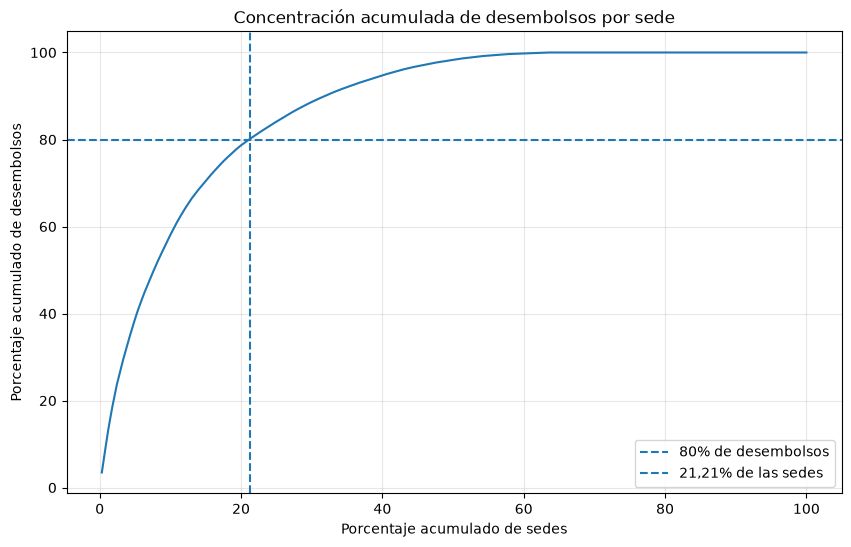

In [27]:
# Calcular el porcentaje acumulado de sedes
desembolsos_por_sede["porcentaje_sedes"] = (
    (desembolsos_por_sede.index + 1) / total_sedes * 100
)

# Construir la gráfica de concentración
plt.figure(figsize=(10, 6))

plt.plot(
    desembolsos_por_sede["porcentaje_sedes"],
    desembolsos_por_sede["participacion_acumulada_pct"]
)

# Líneas de referencia del 80%
plt.axhline(y=80, linestyle="--", label="80% de desembolsos")
plt.axvline(
    x=cantidad_sedes_80 / total_sedes * 100,
    linestyle="--",
    label="21,21% de las sedes"
)

plt.title("Concentración acumulada de desembolsos por sede")
plt.xlabel("Porcentaje acumulado de sedes")
plt.ylabel("Porcentaje acumulado de desembolsos")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## 3.3. Análisis de cohortes, activación y retención

Se analizará el comportamiento de las sedes según su mes de vinculación para comprender su tiempo de activación y la continuidad de su actividad.
El análisis se desarrollará en tres dimensiones:
1. Cohortes de vinculación: agrupación de sedes según el mes en que ingresaron a la red.
2. Tiempo de activación: tiempo transcurrido entre la vinculación y la primera solicitud registrada.
3. Retención activa: proporción de sedes que continúan registrando solicitudes después de su vinculación.

Antes de construir las cohortes, se verificará la consistencia de la información de identificación y vinculación de cada sede.

In [29]:
# Revisar cuántos aliados y fechas de vinculación tiene cada sede
validacion_sedes = (
    df.groupby("sede_id")
    .agg(
        cantidad_aliados=("aliado_id", "nunique"),
        fechas_vinculacion=("fecha_vinculacion", "nunique")
    )
)

# Identificar sedes con más de un aliado o fecha de vinculación
sedes_inconsistentes = validacion_sedes[
    (validacion_sedes["cantidad_aliados"] > 1) |
    (validacion_sedes["fechas_vinculacion"] > 1)
]

print("Total de sedes:", len(validacion_sedes))
print("Sedes con más de un aliado o fecha de vinculación:", len(sedes_inconsistentes))

display(sedes_inconsistentes)

Total de sedes: 330
Sedes con más de un aliado o fecha de vinculación: 0


,cantidad_aliados,fechas_vinculacion
sede_id,,


#### Hallazgos: consistencia de identificación y vinculación

Se verificó que cada sede estuviera asociada a un único aliado y tuviera una única fecha de vinculación durante el periodo analizado.
**Resultados:**
- Total de sedes: 330.
- Sedes asociadas a más de un aliado: 0.
- Sedes con más de una fecha de vinculación: 0.

**Decisión:** utilizar `sede_id` como identificador de cada sede y `fecha_vinculacion` como referencia para construir las cohortes mensuales.

#### 3.3.1 Construcción de cohortes mensuales

Se construirá una tabla consolidada con una fila por sede, utilizando su información de identificación y vinculación.
La cohorte se definirá a partir del mes de vinculación de cada sede. Esta tabla servirá como base para calcular el tiempo de activación y la retención.

In [30]:
# Crear una tabla con una fila por sede
sedes = (
    df.sort_values("mes")
    .groupby("sede_id")
    .agg(
        aliado_id=("aliado_id", "first"),
        sector=("sector", "first"),
        ciudad=("ciudad", "first"),
        canal_origen=("canal_origen", "first"),
        fecha_vinculacion=("fecha_vinculacion", "first"),
        capacitada=("capacitada", "first"),
        hunter_asignado=("hunter_asignado", "first")
    )
    .reset_index()
)

# Crear la cohorte correspondiente al mes de vinculación
sedes["cohorte"] = (
    sedes["fecha_vinculacion"].dt.to_period("M")
)

print("Total de sedes consolidadas:", len(sedes))

# Mostrar las primeras 10 sedes
display(sedes.head(10))

Total de sedes consolidadas: 330


,sede_id,aliado_id,sector,ciudad,canal_origen,fecha_vinculacion,capacitada,hunter_asignado,cohorte
0,S0001,A001,Veterinaria,Otras,Hunter,2026-07-10,Sí,Hunter 1,2026-07
1,S0002,A002,Odontología,Barranquilla,Autogestión,2026-08-19,No,NaN,2026-08
2,S0003,A003,Veterinaria,Cúcuta,Hunter,2025-08-01,Sí,Hunter 4,2025-08
3,S0004,A004,Odontología,Barranquilla,Autogestión,2026-02-21,Sí,NaN,2026-02
4,S0005,A005,Veterinaria,Bogotá,Autogestión,2026-01-08,No,NaN,2026-01
5,S0006,A006,Estética,Bogotá,Hunter,2026-03-12,Sí,Hunter 4,2026-03
6,S0007,A007,Odontología,Cúcuta,Autogestión,2025-11-26,Sí,NaN,2025-11
7,S0008,A008,Veterinaria,Cartagena,Autogestión,2025-05-22,No,NaN,2025-05
8,S0009,A009,Odontología,Barranquilla,Autogestión,2025-06-03,Sí,NaN,2025-06
9,S0010,A010,Veterinaria,Bogotá,Hunter,2026-01-06,Sí,Hunter 1,2026-01


#### 3.3.3 Cálculo del tiempo de activación

Se identificará el primer mes en el que cada sede registró al menos una solicitud (`apps > 0`).
El tiempo de activación se calculará como la diferencia, en meses calendario, entre el mes de vinculación y el mes de la primera solicitud.
Las sedes que no hayan registrado solicitudes durante el periodo analizado se clasificarán como no activadas.

**Limitación:** debido a que la actividad está registrada por mes y no por fecha individual de solicitud, el tiempo de activación se medirá en meses calendario, no en días exactos.

In [31]:
# Identificar el primer mes con solicitudes para cada sede
primeras_solicitudes = (
    df[df["apps"] > 0]
    .groupby("sede_id")["mes"]
    .min()
    .reset_index()
    .rename(columns={"mes": "primer_mes_actividad"})
)

# Incorporar el primer mes de actividad a la tabla de sedes
sedes = sedes.merge(
    primeras_solicitudes,
    on="sede_id",
    how="left"
)

# Calcular los meses transcurridos hasta la activación
sedes["meses_hasta_activacion"] = pd.array(
    [
        primer_mes.to_period("M").ordinal - cohorte.ordinal
        if pd.notna(primer_mes) else pd.NA
        for primer_mes, cohorte in zip(
            sedes["primer_mes_actividad"],
            sedes["cohorte"]
        )
    ],
    dtype="Int64"
)

# Clasificar las sedes según su estado de activación
sedes["estado_activacion"] = sedes["primer_mes_actividad"].apply(
    lambda fecha: "Activada" if pd.notna(fecha) else "No activada"
)

# Resumen de activación
resumen_activacion = (
    sedes["estado_activacion"]
    .value_counts()
    .rename_axis("estado")
    .reset_index(name="cantidad_sedes")
)

display(resumen_activacion)

print(
    "\nPorcentaje de sedes activadas:",
    f"{(sedes['estado_activacion'].eq('Activada').mean() * 100):.2f}%"
)

# Mostrar ejemplos de la información calculada
display(
    sedes[
        [
            "sede_id",
            "cohorte",
            "primer_mes_actividad",
            "meses_hasta_activacion",
            "estado_activacion"
        ]
    ].head(15)
)

,estado,cantidad_sedes
0,Activada,225
1,No activada,105



Porcentaje de sedes activadas: 68.18%


,sede_id,cohorte,primer_mes_actividad,meses_hasta_activacion,estado_activacion
0,S0001,2026-07,2026-09-01,2,Activada
1,S0002,2026-08,NaT,<NA>,No activada
2,S0003,2025-08,2025-11-01,3,Activada
3,S0004,2026-02,2026-06-01,4,Activada
4,S0005,2026-01,NaT,<NA>,No activada
5,S0006,2026-03,2026-06-01,3,Activada
6,S0007,2025-11,2026-02-01,3,Activada
7,S0008,2025-05,2025-06-01,1,Activada
8,S0009,2025-06,NaT,<NA>,No activada
9,S0010,2026-01,2026-03-01,2,Activada


#### Hallazgos preliminares: activación de sedes

De las 330 sedes analizadas, 225 registraron al menos una solicitud durante el periodo de estudio, lo que representa una tasa de activación observada del 68,18%.
Las 105 sedes restantes, equivalentes al 31,82%, no registraron solicitudes durante el periodo observado.

**Interpretación comercial:**

Existe una oportunidad de activación en las sedes vinculadas que todavía no han generado solicitudes. Sin embargo, es necesario considerar la fecha de vinculación y el tiempo de exposición de cada sede antes de concluir que se encuentran inactivas.
El análisis continuará con la distribución del tiempo de activación para identificar cuánto tardan las sedes en comenzar a generar solicitudes.

### 3.3.4. Distribución del tiempo de activación

Se analizará el tiempo transcurrido entre la vinculación y la primera solicitud registrada para las 225 sedes activadas.
Se calcularán las siguientes métricas:

- Tiempo promedio de activación.
- Tiempo mediano de activación.
- Tiempo mínimo y máximo.
- Cantidad de sedes que se activan en cada mes desde su vinculación.

La mediana permitirá complementar el promedio y reducir la influencia de sedes que tardan considerablemente más en activarse.

In [32]:
# Seleccionar únicamente las sedes con activación observada
sedes_activadas = sedes[
    sedes["estado_activacion"] == "Activada"
].copy()

# Calcular estadísticas del tiempo de activación
resumen_tiempo_activacion = sedes_activadas[
    "meses_hasta_activacion"
].describe()

print("Estadísticas del tiempo de activación (meses):")
display(resumen_tiempo_activacion.to_frame(name="meses"))

# Contar cuántas sedes se activaron en cada mes
distribucion_activacion = (
    sedes_activadas["meses_hasta_activacion"]
    .value_counts()
    .sort_index()
    .reset_index()
)

distribucion_activacion.columns = [
    "meses_hasta_activacion",
    "cantidad_sedes"
]

print("Distribución de sedes según tiempo de activación:")
display(distribucion_activacion)

Estadísticas del tiempo de activación (meses):


,meses
count,225.0
mean,3.44
std,1.700105
min,1.0
25%,2.0
50%,3.0
75%,5.0
max,10.0


Distribución de sedes según tiempo de activación:


,meses_hasta_activacion,cantidad_sedes
0,1,34
1,2,41
2,3,42
3,4,35
4,5,60
5,6,6
6,7,4
7,9,2
8,10,1


#### Hallazgos: tiempo de activación

- Se identificaron 330 sedes vinculadas; 225 registraron al menos una solicitud (68,18 %) y 105 no registraron solicitudes (31,82 %) durante el periodo observado.
- Entre las sedes activadas, el tiempo promedio hasta la primera solicitud fue de 3,44 meses y la mediana fue de 3 meses.
- El 75 % de las sedes activadas registró su primera solicitud en un máximo de 5 meses.
- La mayor concentración se presentó en el quinto mes, con 60 sedes activadas.

**Decisión comercial:** medir la activación como un indicador independiente de la vinculación. Las sedes que no registran solicitudes requieren seguimiento, mientras que las sedes recién vinculadas necesitan un periodo de acompañamiento y activación.

**Limitación:** el tiempo se calcula por diferencia entre meses calendario, no por días exactos. Las cohortes recientes tienen menos tiempo de observación.

In [33]:
#### Cobertura mensual por sede

cobertura_mensual = (
    df.groupby("sede_id")
    .agg(
        meses_con_registro=("mes", "nunique"),
        primer_mes_registrado=("mes", "min"),
        ultimo_mes_registrado=("mes", "max")
    )
    .reset_index()
)

display(cobertura_mensual["meses_con_registro"].describe())

print(
    "Sedes con los 12 meses o más de registros:",
    (cobertura_mensual["meses_con_registro"] >= 12).sum()
)

print(
    "Sedes con un solo mes de registro:",
    (cobertura_mensual["meses_con_registro"] == 1).sum()
)

display(
    cobertura_mensual.sort_values(
        "meses_con_registro"
    ).head(15)
)

count    330.000000
mean      11.221212
std        5.861847
min        1.000000
25%        6.000000
50%       10.000000
75%       16.000000
max       24.000000
Name: meses_con_registro, dtype: float64

Sedes con los 12 meses o más de registros: 153
Sedes con un solo mes de registro: 3


,sede_id,meses_con_registro,primer_mes_registrado,ultimo_mes_registrado
27,S0028,1,2026-10-01,2026-10-01
24,S0025,1,2026-10-01,2026-10-01
85,S0086,1,2026-10-01,2026-10-01
255,S0256,2,2026-09-01,2026-10-01
69,S0070,2,2026-09-01,2026-10-01
62,S0063,2,2026-09-01,2026-10-01
64,S0065,2,2026-09-01,2026-10-01
233,S0234,2,2026-09-01,2026-10-01
304,S0305,2,2026-09-01,2026-10-01
268,S0269,2,2026-09-01,2026-10-01


#### Validación de continuidad de registros mensuales

Se verifica si existen meses sin registro entre el primer y el último mes observado para cada sede. Esta validación permite distinguir los meses con actividad cero de los periodos en los que no hay información disponible.
Los meses sin registro no se interpretarán automáticamente como meses inactivos.

In [34]:
# Calcular los meses esperados entre el primer y último registro de cada sede
cobertura_mensual["meses_esperados"] = (
    (
        cobertura_mensual["ultimo_mes_registrado"].dt.year
        - cobertura_mensual["primer_mes_registrado"].dt.year
    ) * 12
    +
    (
        cobertura_mensual["ultimo_mes_registrado"].dt.month
        - cobertura_mensual["primer_mes_registrado"].dt.month
    )
    + 1
)

# Comparar meses esperados contra meses realmente registrados
cobertura_mensual["meses_faltantes"] = (
    cobertura_mensual["meses_esperados"]
    - cobertura_mensual["meses_con_registro"]
)

print("Sedes con meses faltantes dentro de su periodo observado:",
      (cobertura_mensual["meses_faltantes"] > 0).sum())

print("Total de meses faltantes:",
      cobertura_mensual["meses_faltantes"].sum())

display(
    cobertura_mensual[
        cobertura_mensual["meses_faltantes"] > 0
    ].sort_values(
        "meses_faltantes", ascending=False
    ).head(15)
)

Sedes con meses faltantes dentro de su periodo observado: 16
Total de meses faltantes: 17


,sede_id,meses_con_registro,primer_mes_registrado,ultimo_mes_registrado,meses_esperados,meses_faltantes
325,S0326,15,2025-06-01,2026-10-01,17,2
33,S0034,16,2025-06-01,2026-10-01,17,1
61,S0062,14,2025-08-01,2026-10-01,15,1
75,S0076,16,2025-06-01,2026-10-01,17,1
76,S0077,13,2025-09-01,2026-10-01,14,1
119,S0120,5,2026-05-01,2026-10-01,6,1
142,S0143,8,2026-02-01,2026-10-01,9,1
161,S0162,15,2025-07-01,2026-10-01,16,1
166,S0167,15,2025-07-01,2026-10-01,16,1
174,S0175,20,2025-02-01,2026-10-01,21,1


#### Validación de cobertura desde la fecha de vinculación

Se compara el número de meses esperados desde la cohorte de vinculación hasta el último mes observado con los meses que realmente tienen registros.
Esta validación permite identificar si existen periodos sin información desde el inicio de la relación comercial con Welli.

In [35]:
# Calcular meses esperados desde la vinculación hasta el último registro
cobertura_mensual = cobertura_mensual.merge(
    sedes[["sede_id", "cohorte"]],
    on="sede_id",
    how="left"
)

cobertura_mensual["meses_esperados_desde_vinculacion"] = (
    (
        cobertura_mensual["ultimo_mes_registrado"].dt.year
        - cobertura_mensual["cohorte"].dt.year
    ) * 12
    +
    (
        cobertura_mensual["ultimo_mes_registrado"].dt.month
        - cobertura_mensual["cohorte"].dt.month
    )
    + 1
)

cobertura_mensual["meses_sin_registro_desde_vinculacion"] = (
    cobertura_mensual["meses_esperados_desde_vinculacion"]
    - cobertura_mensual["meses_con_registro"]
)

print(
    "Sedes con meses sin registro desde su vinculación:",
    (
        cobertura_mensual[
            "meses_sin_registro_desde_vinculacion"
        ] > 0
    ).sum()
)

print(
    "Total de meses sin registro desde la vinculación:",
    cobertura_mensual[
        "meses_sin_registro_desde_vinculacion"
    ].sum()
)

display(
    cobertura_mensual[
        cobertura_mensual[
            "meses_sin_registro_desde_vinculacion"
        ] > 0
    ][
        [
            "sede_id",
            "cohorte",
            "meses_con_registro",
            "meses_esperados_desde_vinculacion",
            "meses_sin_registro_desde_vinculacion"
        ]
    ].sort_values(
        "meses_sin_registro_desde_vinculacion",
        ascending=False
    ).head(15)
)

Sedes con meses sin registro desde su vinculación: 16
Total de meses sin registro desde la vinculación: 17


,sede_id,cohorte,meses_con_registro,meses_esperados_desde_vinculacion,meses_sin_registro_desde_vinculacion
325,S0326,2025-06,15,17,2
33,S0034,2025-06,16,17,1
61,S0062,2025-08,14,15,1
75,S0076,2025-06,16,17,1
76,S0077,2025-09,13,14,1
119,S0120,2026-05,5,6,1
142,S0143,2026-02,8,9,1
161,S0162,2025-07,15,16,1
166,S0167,2025-07,15,16,1
174,S0175,2025-02,20,21,1


#### 3.3.5 Validación de registros por sede y mes

Se verifica que cada sede tenga como máximo un registro por mes. Esta condición es necesaria para calcular correctamente las sedes activas y observadas en cada periodo de vida de la cohorte.

In [36]:
# Identificar registros repetidos por sede y mes
duplicados_sede_mes = df[
    df.duplicated(
        subset=["sede_id", "mes"],
        keep=False
    )
].sort_values(["sede_id", "mes"])

print(
    "Cantidad de filas involucradas en duplicados sede-mes:",
    len(duplicados_sede_mes)
)

print(
    "Cantidad de combinaciones sede-mes duplicadas:",
    df.duplicated(
        subset=["sede_id", "mes"]
    ).sum()
)

display(duplicados_sede_mes.head(20))

Cantidad de filas involucradas en duplicados sede-mes: 0
Cantidad de combinaciones sede-mes duplicadas: 0


,sede_id,aliado_id,sector,ciudad,canal_origen,hunter_asignado,fecha_vinculacion,capacitada,mes,apps,aprobadas,desembolsos,monto_desembolsado,ticket_promedio_tratamiento,dias_sin_app,desembolsos_en_mora,monto_en_mora


### 3.3.6. Retención mensual por cohortes

Se calcula la proporción de sedes que registran solicitudes en cada mes transcurrido desde su vinculación. Se consideran únicamente las sedes con información disponible en cada periodo.

In [37]:
# Meses transcurridos desde la vinculación
df_cohortes = df.merge(
    sedes[["sede_id", "cohorte"]],
    on="sede_id",
    how="left"
)

df_cohortes["mes_vida"] = (
    (df_cohortes["mes"].dt.year - df_cohortes["cohorte"].dt.year) * 12
    + df_cohortes["mes"].dt.month
    - df_cohortes["cohorte"].dt.month
)

# Identificar actividad mensual
df_cohortes["activa"] = df_cohortes["apps"] > 0

# Calcular sedes observadas y activas por cohorte y mes de vida
retencion = (
    df_cohortes.groupby(["cohorte", "mes_vida"])
    .agg(
        sedes_observadas=("sede_id", "nunique"),
        sedes_activas=("activa", "sum")
    )
    .reset_index()
)

retencion["retencion_pct"] = (
    retencion["sedes_activas"]
    / retencion["sedes_observadas"] * 100
)

# Construir matriz
matriz_retencion = retencion.pivot(
    index="cohorte",
    columns="mes_vida",
    values="retencion_pct"
)

display(matriz_retencion.round(1))

mes_vida,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
cohorte,,,,,,,,,,,,,,,,,,,,,
2024-11,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2024-12,0.0,11.1,33.3,44.4,55.6,77.8,77.8,77.8,77.8,88.9,...,66.7,66.7,66.7,55.6,50.0,55.6,33.3,33.3,33.3,NaN
2025-01,0.0,0.0,28.6,14.3,28.6,71.4,42.9,57.1,57.1,42.9,...,71.4,57.1,71.4,57.1,57.1,42.9,57.1,57.1,NaN,NaN
2025-02,0.0,0.0,0.0,12.5,25.0,37.5,50.0,50.0,62.5,62.5,...,50.0,42.9,25.0,25.0,50.0,50.0,37.5,NaN,NaN,NaN
2025-03,0.0,7.1,7.1,35.7,50.0,42.9,50.0,64.3,57.1,42.9,...,50.0,50.0,50.0,50.0,42.9,21.4,NaN,NaN,NaN,NaN
2025-04,0.0,0.0,0.0,20.0,0.0,20.0,0.0,40.0,0.0,20.0,...,20.0,20.0,40.0,20.0,20.0,NaN,NaN,NaN,NaN,NaN
2025-05,0.0,13.3,20.0,33.3,13.3,66.7,60.0,66.7,60.0,46.7,...,40.0,33.3,33.3,33.3,NaN,NaN,NaN,NaN,NaN,NaN
2025-06,0.0,33.3,44.4,66.7,50.0,75.0,55.6,55.6,77.8,77.8,...,77.8,75.0,62.5,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2025-07,0.0,15.0,30.0,45.0,42.1,75.0,55.0,70.0,70.0,75.0,...,65.0,65.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [38]:
# 3.3.6.1. Actividad mensual consolidada de cohortes comparables

cohortes_maduras = df_cohortes[
    (df_cohortes["cohorte"] <= pd.Period("2026-05", freq="M"))
    & (df_cohortes["mes_vida"].between(1, 5))
]

actividad_meses = (
    cohortes_maduras.groupby("mes_vida")
    .agg(
        sedes_observadas=("sede_id", "nunique"),
        sedes_activas=("activa", "sum")
    )
    .reset_index()
)

actividad_meses["actividad_pct"] = (
    actividad_meses["sedes_activas"]
    / actividad_meses["sedes_observadas"] * 100
)

display(actividad_meses.round(2))

,mes_vida,sedes_observadas,sedes_activas,actividad_pct
0,1,266,26,9.77
1,2,265,59,22.26
2,3,265,91,34.34
3,4,264,106,40.15
4,5,265,168,63.40


### Conclusion 

**Conclusión comercial:** la red presenta una brecha de activación del 31,82 %. Entre las sedes que se activan, el tiempo promedio es de 3,44 meses. La actividad mensual agregada aumenta de 9,77 % en el primer mes a 63,40 % en el quinto.

**Implicación:** Welli debe gestionar la activación como un proceso posterior a la vinculación, con seguimiento y objetivos por etapa. La actividad mensual no debe confundirse con retención continua.

## 3.4. Efecto de la capacitación

Se analiza la relación entre la capacitación de las sedes y su desempeño comercial, comparando activación, solicitudes, desembolsos y mora entre sedes capacitadas y no capacitadas.

**Objetivo:** identificar si la capacitación está asociada con mejores resultados de activación y desempeño comercial.

**Consideración metodológica:** el análisis es descriptivo y no permite atribuir causalidad a la capacitación, debido a que no se conoce el criterio de selección de las sedes capacitadas.

In [39]:
# 3.4.1. Comparación de resultados según capacitación

capacitacion_sedes = (
    df.groupby("sede_id")
    .agg(
        valores_capacitacion=("capacitada", "nunique"),
        capacitada=("capacitada", "first"),
        apps=("apps", "sum"),
        desembolsos=("desembolsos", "sum"),
        monto_desembolsado=("monto_desembolsado", "sum"),
        mora=("desembolsos_en_mora", "sum")
    )
    .reset_index()
    .merge(
        sedes[["sede_id", "estado_activacion"]],
        on="sede_id",
        how="left"
    )
)

print(
    "Sedes con cambios en el registro de capacitación:",
    (capacitacion_sedes["valores_capacitacion"] > 1).sum()
)

resumen_capacitacion = (
    capacitacion_sedes[
        capacitacion_sedes["capacitada"].isin(["Sí", "No"])
    ]
    .groupby("capacitada")
    .agg(
        sedes=("sede_id", "nunique"),
        activadas=("estado_activacion",
                   lambda x: (x == "Activada").sum()),
        solicitudes=("apps", "sum"),
        desembolsos=("desembolsos", "sum"),
        monto_desembolsado=("monto_desembolsado", "sum"),
        desembolsos_en_mora=("mora", "sum")
    )
    .reset_index()
)

resumen_capacitacion["pct_activacion"] = (
    resumen_capacitacion["activadas"]
    / resumen_capacitacion["sedes"] * 100
)

display(resumen_capacitacion.round(2))

Sedes con cambios en el registro de capacitación: 0


,capacitada,sedes,activadas,solicitudes,desembolsos,monto_desembolsado,desembolsos_en_mora,pct_activacion
0,No,104,47,649,255,777600000,10,45.19
1,Sí,226,178,10555,4793,10166030000,235,78.76


**Hallazgos:**

- Las sedes capacitadas presentan una activación del 78,76 %, frente al 45,19 % de las no capacitadas.
- Registran aproximadamente 7,5 veces más solicitudes por sede y 6 veces más monto desembolsado por sede.
- La proporción de desembolsos en mora es ligeramente superior en las sedes capacitadas: 4,90 % frente a 3,92 %.

**Conclusión comercial:** la capacitación está asociada con mejores niveles de activación y producción comercial. Se recomienda priorizar el acompañamiento y medir sus resultados mediante un piloto controlado.

**Limitación:** el análisis es descriptivo y no demuestra causalidad. Las diferencias pueden estar relacionadas con selección de sedes, antigüedad y exposición comercial. La mora también depende de la madurez de las cohortes.

## 3.5. Comparación del desempeño por segmento

Se compara el desempeño comercial según sector, ciudad, canal de origen y tamaño del aliado. Se consideran el número de sedes, activación, solicitudes, desembolsos, monto desembolsado y mora.

**Objetivo:** identificar los segmentos con mayor actividad y potencial comercial, considerando tanto volumen como calidad.

In [40]:
# Consolidar resultados comerciales por sede
desempeno_sedes = (
    df.groupby("sede_id")
    .agg(
        aliado_id=("aliado_id", "first"),
        sector=("sector", "first"),
        ciudad=("ciudad", "first"),
        canal_origen=("canal_origen", "first"),
        apps=("apps", "sum"),
        aprobadas=("aprobadas", "sum"),
        desembolsos=("desembolsos", "sum"),
        monto_desembolsado=("monto_desembolsado", "sum"),
        mora=("desembolsos_en_mora", "sum")
    )
    .reset_index()
    .merge(
        sedes[["sede_id", "estado_activacion"]],
        on="sede_id",
        how="left"
    )
)

# Calcular el tamaño de cada aliado
tamano_aliados = (
    sedes.groupby("aliado_id")
    .agg(cantidad_sedes=("sede_id", "nunique"))
    .reset_index()
)

desempeno_sedes = desempeno_sedes.merge(
    tamano_aliados,
    on="aliado_id",
    how="left"
)

# Clasificar aliados según número de sedes
desempeno_sedes["tamano_aliado"] = pd.cut(
    desempeno_sedes["cantidad_sedes"],
    bins=[0, 1, 3, float("inf")],
    labels=["1 sede", "2-3 sedes", "4 o más sedes"]
)

desempeno_sedes.head()

,sede_id,aliado_id,sector,ciudad,canal_origen,apps,aprobadas,desembolsos,monto_desembolsado,mora,estado_activacion,cantidad_sedes,tamano_aliado
0,S0001,A001,Veterinaria,Otras,Hunter,7,7,4,4740000,0,Activada,1,1 sede
1,S0002,A002,Odontología,Barranquilla,Autogestión,0,0,0,0,0,No activada,1,1 sede
2,S0003,A003,Veterinaria,Cúcuta,Hunter,31,19,10,7680000,2,Activada,1,1 sede
3,S0004,A004,Odontología,Barranquilla,Autogestión,182,116,85,169970000,2,Activada,1,1 sede
4,S0005,A005,Veterinaria,Bogotá,Autogestión,0,0,0,0,0,No activada,1,1 sede


In [41]:
def resumen_segmento(df, segmento):
    resumen = (
        df.groupby(segmento, observed=True)
        .agg(
            sedes=("sede_id", "nunique"),
            aliados=("aliado_id", "nunique"),
            activadas=("estado_activacion", 
                       lambda x: (x == "Activada").sum()),
            apps=("apps", "sum"),
            aprobadas=("aprobadas", "sum"),
            desembolsos=("desembolsos", "sum"),
            monto_desembolsado=("monto_desembolsado", "sum"),
            mora=("mora", "sum")
        )
    )

    resumen["activacion_pct"] = (
        resumen["activadas"] / resumen["sedes"] * 100
    ).round(2)

    resumen["conversion_apps_desembolso_pct"] = (
        resumen["desembolsos"] / resumen["apps"].replace(0, np.nan) * 100
    ).round(2)

    resumen["mora_pct"] = (
        resumen["mora"] / resumen["desembolsos"].replace(0, np.nan) * 100
    ).round(2)

    resumen["monto_por_sede"] = (
        resumen["monto_desembolsado"] / resumen["sedes"]
    ).round(0)

    return resumen.sort_values("monto_desembolsado", ascending=False)


resumen_sector = resumen_segmento(desempeno_sedes, "sector")
resumen_ciudad = resumen_segmento(desempeno_sedes, "ciudad")
resumen_canal = resumen_segmento(desempeno_sedes, "canal_origen")

display(resumen_sector)
display(resumen_ciudad)
display(resumen_canal)

,sedes,aliados,activadas,apps,aprobadas,desembolsos,monto_desembolsado,mora,activacion_pct,conversion_apps_desembolso_pct,mora_pct,monto_por_sede
sector,,,,,,,,,,,,
Odontología,188,101,130,8254,5509,3755,7539520000,180,69.15,45.49,4.79,40103830.0
Estética,40,25,30,1082,707,542,2035640000,12,75.00,50.09,2.21,50891000.0
Equipos médicos,10,7,5,54,29,24,381930000,2,50.00,44.44,8.33,38193000.0
Dermatología,21,14,12,253,172,132,353610000,3,57.14,52.17,2.27,16838571.0
Óptica,28,20,17,740,500,289,333260000,24,60.71,39.05,8.30,11902143.0
Veterinaria,43,32,31,821,585,306,299670000,24,72.09,37.27,7.84,6969070.0


,sedes,aliados,activadas,apps,aprobadas,desembolsos,monto_desembolsado,mora,activacion_pct,conversion_apps_desembolso_pct,mora_pct,monto_por_sede
ciudad,,,,,,,,,,,,
Bogotá,116,82,75,4469,2995,1981,3816900000,89,64.66,44.33,4.49,32904310.0
Barranquilla,32,28,22,1478,963,662,1503930000,38,68.75,44.79,5.74,46997812.0
Cali,49,38,37,1244,824,565,1110940000,41,75.51,45.42,7.26,22672245.0
Medellín,40,34,25,934,625,435,1082900000,26,62.50,46.57,5.98,27072500.0
Bucaramanga,23,20,16,581,396,283,1068820000,15,69.57,48.71,5.30,46470435.0
Otras,18,17,11,823,576,397,795700000,14,61.11,48.24,3.53,44205556.0
Cartagena,14,14,11,612,421,285,667710000,10,78.57,46.57,3.51,47693571.0
Cúcuta,19,18,14,702,467,291,543900000,10,73.68,41.45,3.44,28626316.0
Pereira,19,16,14,361,235,149,352830000,2,73.68,41.27,1.34,18570000.0


,sedes,aliados,activadas,apps,aprobadas,desembolsos,monto_desembolsado,mora,activacion_pct,conversion_apps_desembolso_pct,mora_pct,monto_por_sede
canal_origen,,,,,,,,,,,,
Hunter,139,86,107,6015,3899,2603,5202420000,149,76.98,43.28,5.72,37427482.0
Alianza estratégica,121,28,83,4537,3184,2158,5070550000,81,68.60,47.56,3.75,41905372.0
Autogestión,70,70,35,652,419,287,670660000,15,50.00,44.02,5.23,9580857.0


In [42]:
resumen_tamano = resumen_segmento(
    desempeno_sedes,
    "tamano_aliado"
)

display(resumen_tamano)

,sedes,aliados,activadas,apps,aprobadas,desembolsos,monto_desembolsado,mora,activacion_pct,conversion_apps_desembolso_pct,mora_pct,monto_por_sede
tamano_aliado,,,,,,,,,,,,
4 o más sedes,112,17,76,4234,2933,1987,4454790000,94,67.86,46.93,4.73,39774911.0
1 sede,131,131,85,4704,3094,2091,4279870000,112,64.89,44.45,5.36,32670763.0
2-3 sedes,87,36,64,2266,1475,970,2208970000,39,73.56,42.81,4.02,25390460.0


### 3.5.1. Hallazgos por sector, ciudad y canal

**Por sector**
- Odontología concentra el mayor volumen, con 7.539 millones desembolsados.
- Estética presenta la mayor activación (75 %) y el mayor monto por sede (50,9 millones).
- Dermatología registra la menor mora relativa (2,21 %), seguida de Estética (2,27 %).

**Por ciudad**
- Bogotá lidera el volumen, con 3.817 millones desembolsados.
- Barranquilla y Bucaramanga destacan por su monto promedio por sede, cercano a 47 millones.
- Cartagena presenta la mayor activación (78,57 %), mientras que Pereira registra la menor mora (1,34 %).

**Por canal**
- Hunter concentra el mayor volumen desembolsado (5.202 millones) y la mayor activación (76,98 %).
- Alianza estratégica presenta la mejor conversión de solicitudes a desembolsos (47,56 %) y la menor mora (3,75 %).
- Autogestión registra la menor activación (50 %) y el menor monto por sede (9,6 millones).

**Conclusión comercial:** Odontología es el principal motor de volumen; Estética destaca por productividad y calidad relativa; Alianza estratégica combina conversión y mora favorables. Bogotá concentra la escala, mientras que Cartagena, Barranquilla y Bucaramanga muestran oportunidades para profundizar.

**Limitación:** los resultados son descriptivos. Las diferencias de mora deben interpretarse considerando la antigüedad y madurez de las cohortes de desembolso. Los segmentos con pocas sedes requieren validación antes de tomar decisiones de expansión.

### 3.5.2. Desempeño según tamaño del aliado

Se agrupan los aliados según el número de sedes vinculadas: una sede, entre dos y tres sedes, y cuatro o más sedes.

**Objetivo:** evaluar la relación entre el tamaño de la red del aliado, su activación, conversión, volumen de desembolsos y mora.

In [44]:
resumen_tamano = resumen_segmento(
    desempeno_sedes,
    "tamano_aliado"
)

display(resumen_tamano)

,sedes,aliados,activadas,apps,aprobadas,desembolsos,monto_desembolsado,mora,activacion_pct,conversion_apps_desembolso_pct,mora_pct,monto_por_sede
tamano_aliado,,,,,,,,,,,,
4 o más sedes,112,17,76,4234,2933,1987,4454790000,94,67.86,46.93,4.73,39774911.0
1 sede,131,131,85,4704,3094,2091,4279870000,112,64.89,44.45,5.36,32670763.0
2-3 sedes,87,36,64,2266,1475,970,2208970000,39,73.56,42.81,4.02,25390460.0


**Hallazgos:**

- Los aliados de 4 o más sedes concentran el mayor monto desembolsado (4.455 millones) y presentan el mayor monto promedio por sede (39,8 millones).
- Los aliados de 2–3 sedes registran la mayor activación (73,56 %) y la menor mora relativa (4,02 %).
- Los aliados de una sede representan 131 aliados y generan 4.280 millones, por lo que también constituyen un segmento relevante.

**Conclusión comercial:** se recomienda priorizar el crecimiento de aliados de 4 o más sedes por su escala y productividad, mientras se desarrolla el segmento de 2–3 sedes por sus indicadores de activación y mora. Los aliados de una sede pueden gestionarse mediante procesos estandarizados y seguimiento proporcional a su potencial.

**Limitación:** el tamaño del aliado no demuestra por sí mismo una mejor calidad comercial. Los resultados deben complementarse con antigüedad, sector, canal y madurez de las cohortes de desembolso antes de definir prioridades.

## 3.6. Definición de un buen aliado

Se define un buen aliado como aquel que genera actividad comercial, mantiene una productividad consistente y presenta indicadores favorables de calidad de cartera.
Se evaluarán tres dimensiones:

1. **Activación:** porcentaje de sus sedes que han generado solicitudes.
2. **Productividad:** monto desembolsado promedio por sede activada.
3. **Calidad:** proporción de desembolsos en mora sobre el total de desembolsos.

**Consideración metodológica:** los indicadores permiten una evaluación descriptiva del desempeño. La mora debe interpretarse considerando la antigüedad de los desembolsos y la madurez de cada cohorte.

In [45]:
# Consolidar resultados por aliado
desempeno_aliados = (
    desempeno_sedes.groupby("aliado_id")
    .agg(
        sedes=("sede_id", "nunique"),
        sedes_activadas=("estado_activacion",
                         lambda x: (x == "Activada").sum()),
        apps=("apps", "sum"),
        desembolsos=("desembolsos", "sum"),
        monto_desembolsado=("monto_desembolsado", "sum"),
        mora=("mora", "sum")
    )
    .reset_index()
)

# Calcular indicadores
desempeno_aliados["activacion_pct"] = (
    desempeno_aliados["sedes_activadas"]
    / desempeno_aliados["sedes"] * 100
)

desempeno_aliados["monto_por_sede_activada"] = (
    desempeno_aliados["monto_desembolsado"]
    / desempeno_aliados["sedes_activadas"].replace(0, np.nan)
)

desempeno_aliados["mora_pct"] = (
    desempeno_aliados["mora"]
    / desempeno_aliados["desembolsos"].replace(0, np.nan) * 100
)

# Resumen estadístico de los indicadores
display(
    desempeno_aliados[
        ["activacion_pct", "monto_por_sede_activada", "mora_pct"]
    ].describe(percentiles=[0.25, 0.50, 0.75]).round(2)
)

,activacion_pct,monto_por_sede_activada,mora_pct
count,184.00,1.340000e+02,123.00
mean,66.89,4.784555e+07,5.20
std,43.94,6.956834e+07,11.40
min,0.00,0.000000e+00,0.00
25%,0.00,5.907500e+06,0.00
50%,100.00,1.837500e+07,0.83
75%,100.00,5.718250e+07,6.67
max,100.00,3.300100e+08,100.00


**Hallazgos:**

- La activación mediana es del 100 %, aunque el 25 % de los aliados presenta activación de 0 %.
- El monto mediano desembolsado por sede activada es de $18,38 millones.
- La mora mediana es del 0,83 % entre los aliados con desembolsos, mientras que el percentil 75 alcanza el 6,67 %.
- Existe una alta dispersión en productividad, lo que indica diferencias importantes entre aliados.

**Conclusión:** un buen aliado debe combinar activación, productividad y calidad de cartera. El volumen desembolsado por sí solo no es suficiente para evaluar su desempeño.

**Limitación:** los indicadores son descriptivos. Los aliados sin desembolsos no tienen una tasa de mora calculable y no deben clasificarse automáticamente como aliados de mala calidad. Además, las diferencias de antigüedad y madurez de los desembolsos pueden afectar la comparación.

In [46]:
# Crear indicadores de cumplimiento
desempeno_aliados["cumple_activacion"] = (
    desempeno_aliados["activacion_pct"] > 0
)

desempeno_aliados["cumple_productividad"] = (
    desempeno_aliados["monto_por_sede_activada"] >= 18_375_000
)

desempeno_aliados["cumple_calidad"] = (
    desempeno_aliados["mora_pct"] <= 6.67
)

# Clasificar aliados
desempeno_aliados["clasificacion"] = np.select(
    [
        (
            desempeno_aliados["cumple_activacion"]
            & desempeno_aliados["cumple_productividad"]
            & desempeno_aliados["cumple_calidad"]
        ),
        (
            desempeno_aliados["cumple_activacion"]
            & desempeno_aliados["cumple_productividad"]
        )
    ],
    [
        "Buen aliado",
        "Potencial - calidad pendiente"
    ],
    default="Por desarrollar"
)

# Revisar distribución
display(
    desempeno_aliados["clasificacion"]
    .value_counts()
    .to_frame("cantidad_aliados")
)

,cantidad_aliados
clasificacion,
Por desarrollar,117
Buen aliado,52
Potencial - calidad pendiente,15


**Resultados de la clasificación inicial:**

- 52 aliados (28,26 %) cumplen los tres criterios establecidos.
- 15 aliados (8,15 %) cumplen activación y productividad, pero requieren evaluación adicional de calidad.
- 117 aliados (63,59 %) se encuentran en la categoría por desarrollar.

**Conclusión comercial:** existe una oportunidad de crecimiento mediante la identificación y gestión diferenciada de los aliados con mejor desempeño. Los 52 aliados clasificados como buenos constituyen una primera base para estrategias de fidelización y expansión.

**Limitación:** la clasificación es preliminar y utiliza umbrales basados en la distribución histórica de los datos. La categoría por desarrollar agrupa situaciones diferentes, como sedes sin activación y aliados con baja productividad. Se requiere separar estos casos antes de definir acciones.

In [47]:
# Desglosar aliados por activación y productividad
revision_aliados = (
    desempeno_aliados.groupby(
        ["cumple_activacion", "cumple_productividad"],
        dropna=False
    )
    .agg(
        cantidad_aliados=("aliado_id", "nunique"),
        monto_total=("monto_desembolsado", "sum"),
        desembolsos=("desembolsos", "sum")
    )
    .reset_index()
)

display(revision_aliados)

,cumple_activacion,cumple_productividad,cantidad_aliados,monto_total,desembolsos
0,False,False,50,0,0
1,True,False,67,667360000,455
2,True,True,67,10276270000,4593


**Hallazgos:**

- 50 aliados (27,17 %) no presentan activación ni desembolsos.
- 67 aliados (36,41 %) están activados, pero tienen una productividad inferior a la mediana de referencia. En conjunto generan 667,36 millones.
- 67 aliados (36,41 %) cumplen los criterios de activación y productividad y concentran 10.276,27 millones, aproximadamente el 93,9 % del monto desembolsado por la red.

**Conclusión comercial:** se identifican tres grupos con necesidades diferentes: reactivación o diagnóstico para aliados sin actividad, acompañamiento para aliados con baja productividad y estrategias de crecimiento y fidelización para aliados con mayor desempeño.

**Implicación:** la gestión comercial debe diferenciar entre aliados sin activación y aliados activos de baja productividad. No conviene aplicar la misma estrategia a ambos grupos.

In [48]:
# Clasificación comercial diferenciada
condiciones = [
    (
        desempeno_aliados["cumple_activacion"]
        & desempeno_aliados["cumple_productividad"]
        & desempeno_aliados["cumple_calidad"]
    ),
    (
        desempeno_aliados["cumple_activacion"]
        & desempeno_aliados["cumple_productividad"]
    ),
    desempeno_aliados["cumple_activacion"],
    ~desempeno_aliados["cumple_activacion"]
]

categorias = [
    "Buen aliado",
    "Potencial - revisar calidad",
    "Baja productividad",
    "Sin activar"
]

desempeno_aliados["clasificacion_final"] = np.select(
    condiciones,
    categorias,
    default="Sin clasificar"
)

display(
    desempeno_aliados["clasificacion_final"]
    .value_counts()
    .to_frame("cantidad_aliados")
)

,cantidad_aliados
clasificacion_final,
Baja productividad,67
Buen aliado,52
Sin activar,50
Potencial - revisar calidad,15


**Resultados de la clasificación final:**

- **Buen aliado:** 52 (28,26 %). Cumplen los criterios de activación, productividad y calidad.
- **Potencial - revisar calidad:** 15 (8,15 %). Cumplen activación y productividad, pero requieren revisión de mora.
- **Baja productividad:** 67 (36,41 %). Están activados, pero no alcanzan el umbral de productividad.
- **Sin activar:** 50 (27,17 %). No han generado solicitudes ni desembolsos.

**Conclusión comercial:** la red requiere estrategias diferenciadas. Se recomienda impulsar la expansión de los buenos aliados, revisar la calidad de los potenciales, mejorar la productividad de los aliados activos y diagnosticar las causas de inactividad de los aliados sin activar.

**Limitación:** la clasificación es una segmentación inicial basada en umbrales estadísticos históricos, no una política definitiva de riesgo. Debe validarse considerando la antigüedad de cada aliado y la madurez de sus desembolsos.

## 3.7. Priorización de aliados y construcción del Top 10

### 3.7.1. Definición del scoring comercial

Se construye un scoring de 0 a 100 puntos para priorizar aliados según cinco variables:

| Variable | Peso |
|---|---:|
| Activación | 20 % |
| Productividad por sede activada | 25 % |
| Conversión de solicitudes a desembolsos | 20 % |
| Calidad de cartera (menor mora) | 25 % |
| Tamaño de la red | 10 % |

**Metodología:** cada variable se transforma en una puntuación relativa mediante percentiles. Para la calidad, una menor proporción de desembolsos en mora representa una mejor puntuación.

**Consideración:** los aliados sin desembolsos no tienen una calidad de cartera evaluable. Se mantienen separados del ranking principal para evitar asignarles una puntuación de calidad sin evidencia.

Los porcentajes (20 %, 25 %, 20 %, 25 % y 10 %) son ponderaciones propuestas por criterio de negocio, no porcentajes calculados directamente de los datos ni establecidos por Welli.

In [49]:
# Calcular conversión de solicitudes a desembolsos
desempeno_aliados["conversion_pct"] = (
    desempeno_aliados["desembolsos"]
    / desempeno_aliados["apps"].replace(0, np.nan) * 100
)

# Crear puntuaciones relativas (percentiles)
desempeno_aliados["score_activacion"] = (
    desempeno_aliados["activacion_pct"].rank(pct=True) * 100
)

desempeno_aliados["score_productividad"] = (
    desempeno_aliados["monto_por_sede_activada"].rank(pct=True) * 100
)

desempeno_aliados["score_conversion"] = (
    desempeno_aliados["conversion_pct"].rank(pct=True) * 100
)

# Menor mora = mayor puntuación
desempeno_aliados["score_calidad"] = (
    desempeno_aliados["mora_pct"].rank(
        ascending=False,
        pct=True
    ) * 100
)

desempeno_aliados["score_tamano"] = (
    desempeno_aliados["sedes"].rank(pct=True) * 100
)

# Calcular scoring ponderado
desempeno_aliados["score_total"] = (
    desempeno_aliados["score_activacion"] * 0.20
    + desempeno_aliados["score_productividad"] * 0.25
    + desempeno_aliados["score_conversion"] * 0.20
    + desempeno_aliados["score_calidad"] * 0.25
    + desempeno_aliados["score_tamano"] * 0.10
)

# Separar aliados con calidad evaluable
aliados_evaluables = (
    desempeno_aliados[
        desempeno_aliados["mora_pct"].notna()
    ]
    .copy()
)

# Ordenar por puntuación
aliados_evaluables = aliados_evaluables.sort_values(
    "score_total",
    ascending=False
)

display(
    aliados_evaluables[
        [
            "aliado_id",
            "sedes",
            "activacion_pct",
            "monto_por_sede_activada",
            "conversion_pct",
            "mora_pct",
            "score_total"
        ]
    ].head(10).round(2)
)

,aliado_id,sedes,activacion_pct,monto_por_sede_activada,conversion_pct,mora_pct,score_total
58,A059,1,100.0,132300000.0,54.84,0.00,76.31
152,A153,2,100.0,32500000.0,58.54,0.00,74.96
112,A113,1,100.0,77640000.0,56.10,0.00,74.18
33,A034,5,100.0,36144000.0,46.99,0.00,73.46
19,A020,1,100.0,63420000.0,50.00,0.00,72.17
26,A027,1,100.0,51340000.0,56.52,0.00,72.09
126,A127,1,100.0,155390000.0,60.42,1.72,70.89
166,A167,8,100.0,20478750.0,47.06,0.00,70.28
15,A016,1,100.0,278490000.0,49.14,1.40,69.91
79,A080,1,100.0,27080000.0,60.00,0.00,69.78


In [50]:
top_10_aliados = aliados_evaluables.head(10).copy()

display(
    top_10_aliados[
        [
            "aliado_id",
            "sedes",
            "desembolsos",
            "mora",
            "mora_pct",
            "monto_desembolsado",
            "score_total"
        ]
    ].round(2)
)

,aliado_id,sedes,desembolsos,mora,mora_pct,monto_desembolsado,score_total
58,A059,1,17,0,0.00,132300000,76.31
152,A153,2,24,0,0.00,65000000,74.96
112,A113,1,23,0,0.00,77640000,74.18
33,A034,5,86,0,0.00,180720000,73.46
19,A020,1,22,0,0.00,63420000,72.17
26,A027,1,26,0,0.00,51340000,72.09
126,A127,1,58,1,1.72,155390000,70.89
166,A167,8,80,0,0.00,163830000,70.28
15,A016,1,143,2,1.40,278490000,69.91
79,A080,1,9,0,0.00,27080000,69.78


### 3.7.3. Interpretación del Top 10

El scoring identifica diez aliados con alto desempeño relativo en activación, productividad, conversión, calidad y tamaño de red.

**Hallazgos principales:**

- 8 de los 10 aliados no registran desembolsos en mora.
- A016 presenta el mayor volumen del grupo, con 143 desembolsos y $278,49 millones.
- A034 y A167 destacan por su tamaño de red, con 5 y 8 sedes, respectivamente.
- A127 registra 58 desembolsos y una proporción de mora de 1,72 %.

**Decisión comercial:** priorizar estos aliados para acciones de retención, expansión de sedes y aumento de actividad comercial. La estrategia debe adaptarse al potencial y desempeño de cada aliado.

**Limitación:** el ranking es relativo al conjunto de aliados evaluados y depende de las ponderaciones propuestas. Una mora de 0 % significa que no se registraron desembolsos en mora en el periodo observado; no garantiza ausencia de riesgo futuro.

## 3.8. Lead scoring: priorización de nuevos aliados

El lead scoring permite ordenar los prospectos según su potencial comercial antes de que ingresen a la red de Welli.

Se proponen cinco variables disponibles durante el primer contacto:

- Número de sedes: 25 %.
- Afinidad del sector: 20 %.
- Oportunidad geográfica: 20 %.
- Canal de origen: 15 %.
- Potencial de financiación declarado: 20 %.

**Restricción metodológica:** el modelo no utiliza desembolsos, conversiones ni mora histórica, porque un lead todavía no tiene comportamiento dentro de Welli.

Las ponderaciones son una hipótesis inicial que deberá validarse con resultados del proceso comercial.

### 3.8.1. Parámetros y escalas del lead scoring

Se establece una escala de puntuación de 0 a 100 para cada variable. El resultado final corresponde a una suma ponderada de los cinco criterios.

| Variable | Criterio | Puntuación |
|---|---|---:|
| **Número de sedes** | 1 sede | 20 |
| | 2–3 sedes | 50 |
| | 4–5 sedes | 75 |
| | Más de 5 sedes | 100 |
| **Afinidad del sector** | Alta | 100 |
| | Media | 60 |
| | Baja | 20 |
| **Cobertura geográfica** | Consolidada | 100 |
| | Intermedia | 60 |
| | Limitada | 20 |
| **Canal de origen** | Alianza estratégica | 100 |
| | Hunter | 80 |
| | Autogestión | 60 |
| **Potencial de financiación** | Alto | 100 |
| | Medio | 60 |
| | Bajo | 20 |

**Ponderaciones:**

- Número de sedes: 25 %.
- Afinidad del sector: 20 %.
- Cobertura geográfica: 20 %.
- Canal de origen: 15 %.
- Potencial de financiación: 20 %.

**Fórmula:**

\[
Score = \sum_{i=1}^{5}(Puntuación_i \times Peso_i)
\]

**Clasificación comercial propuesta:**

- **Prioridad alta:** score ≥ 75.
- **Prioridad media:** score entre 50 y 74,99.
- **Prioridad baja:** score menor a 50.

**Consideraciones metodológicas:**

- Las puntuaciones y ponderaciones son hipótesis iniciales de negocio, no parámetros aprendidos de los datos.
- La afinidad sectorial y la cobertura geográfica deben definirse según la estrategia de expansión de Welli.
- El potencial de financiación se obtiene mediante preguntas al prospecto durante la calificación inicial.
- El modelo utiliza únicamente información disponible al momento de recibir el lead, sin recurrir a resultados crediticios históricos.

In [52]:
def calcular_lead_score(
    numero_sedes,
    afinidad_sector,
    cobertura_geografica,
    canal_origen,
    potencial_financiacion
):
    # Puntuación según número de sedes
    if numero_sedes == 1:
        score_sedes = 20
    elif numero_sedes <= 3:
        score_sedes = 50
    elif numero_sedes <= 5:
        score_sedes = 75
    else:
        score_sedes = 100

    # Escalas de puntuación
    escalas = {
        "alta": 100,
        "media": 60,
        "baja": 20
    }

    score_sector = escalas[afinidad_sector]
    score_ciudad = escalas[cobertura_geografica]
    score_financiacion = escalas[potencial_financiacion]

    score_canal = {
        "Alianza estratégica": 100,
        "Hunter": 80,
        "Autogestión": 60
    }[canal_origen]

    # Scoring ponderado
    score_total = (
        score_sedes * 0.25
        + score_sector * 0.20
        + score_ciudad * 0.20
        + score_canal * 0.15
        + score_financiacion * 0.20
    )

    # Clasificación comercial
    if score_total >= 75:
        prioridad = "Alta"
    elif score_total >= 50:
        prioridad = "Media"
    else:
        prioridad = "Baja"

    return round(score_total, 2), prioridad

In [53]:
# Definir dos leads ficticios
leads = [
    {
        "lead": "Lead A - Red odontológica",
        "numero_sedes": 6,
        "afinidad_sector": "alta",
        "cobertura_geografica": "alta",
        "canal_origen": "Alianza estratégica",
        "potencial_financiacion": "alta"
    },
    {
        "lead": "Lead B - Centro veterinario",
        "numero_sedes": 2,
        "afinidad_sector": "media",
        "cobertura_geografica": "media",
        "canal_origen": "Hunter",
        "potencial_financiacion": "media"
    }
]

# Calcular puntuaciones
resultados_leads = []

for lead in leads:
    score, prioridad = calcular_lead_score(
        lead["numero_sedes"],
        lead["afinidad_sector"],
        lead["cobertura_geografica"],
        lead["canal_origen"],
        lead["potencial_financiacion"]
    )

    resultados_leads.append({
        "lead": lead["lead"],
        "score_total": score,
        "prioridad": prioridad
    })

df_leads = pd.DataFrame(resultados_leads)

display(df_leads)

,lead,score_total,prioridad
0,Lead A - Red odontológica,100.0,Alta
1,Lead B - Centro veterinario,60.5,Media


### 3.8.2. Resultados e interpretación

La evaluación de dos leads ficticios muestra cómo el scoring permite priorizar prospectos según su potencial comercial.

- **Lead A – Red odontológica:** obtiene 100 puntos y prioridad alta. Se recomienda asignar un Hunter para gestionar la vinculación y evaluar la expansión de la red.
- **Lead B – Centro veterinario:** obtiene 60,5 puntos y prioridad media. Se recomienda realizar seguimiento y profundizar en la validación de su potencial de financiación.

**Decisión comercial:** utilizar el score para distribuir los esfuerzos de adquisición, reservando la atención comercial más intensiva para los prospectos de mayor potencial.

**Limitación:** los resultados son ejemplos ilustrativos, no predicciones de desembolsos ni garantías de desempeño futuro. Los criterios y umbrales deberán validarse con resultados reales de adquisición y activación.

In [54]:
# Calcular periodo de observación
meses_observados = df["mes"].nunique()

# Calcular indicadores mensuales promedio
resumen_mensual = pd.DataFrame({
    "indicador": [
        "Desembolsos promedio por mes",
        "Monto desembolsado promedio por mes"
    ],
    "valor": [
        df["desembolsos"].sum() / meses_observados,
        df["monto_desembolsado"].sum() / meses_observados
    ]
})

print("Meses observados:", meses_observados)
display(resumen_mensual.round(2))

Meses observados: 24


,indicador,valor
0,Desembolsos promedio por mes,2.103300e+02
1,Monto desembolsado promedio por mes,4.559846e+08


### 3.9.1. Línea base de desembolsos

Se utiliza el histórico de 24 meses para establecer el nivel de desembolsos actual de Welli.

**Resultados:**

- Desembolsos promedio mensual: 210,33.
- Monto desembolsado promedio mensual: $455,98 millones.
- Sedes registradas: 330.
- Sedes activadas: 225 (68,18 %).

**Interpretación comercial:** la red genera aproximadamente 210 desembolsos y $455,98 millones mensuales. Estos valores constituyen la referencia para estimar el crecimiento incremental.

**Consideración metodológica:** los promedios históricos describen el comportamiento agregado de la red y no representan una garantía de productividad futura. La proyección deberá considerar la activación efectiva, la productividad de las sedes y la calidad de los desembolsos.

In [55]:
# Identificar sedes con solicitudes en cada mes
sedes_activas_mes = (
    df[df["apps"] > 0]
    .groupby("mes")
    .agg(sedes_activas=("sede_id", "nunique"))
)

# Consolidar actividad y resultados mensuales
actividad_mensual = (
    df.groupby("mes")
    .agg(
        desembolsos=("desembolsos", "sum"),
        monto_desembolsado=("monto_desembolsado", "sum")
    )
    .join(sedes_activas_mes)
    .fillna({"sedes_activas": 0})
)

# Calcular productividad por sede activa
actividad_mensual["desembolsos_por_sede_activa"] = (
    actividad_mensual["desembolsos"]
    / actividad_mensual["sedes_activas"].replace(0, np.nan)
)

actividad_mensual["monto_por_sede_activa"] = (
    actividad_mensual["monto_desembolsado"]
    / actividad_mensual["sedes_activas"].replace(0, np.nan)
)

# Resumen del periodo
productividad_base = pd.DataFrame({
    "indicador": [
        "Sedes activas-mes",
        "Desembolsos por sede activa-mes",
        "Monto por sede activa-mes"
    ],
    "valor": [
        actividad_mensual["sedes_activas"].sum(),
        actividad_mensual["desembolsos"].sum() / actividad_mensual["sedes_activas"].sum(),
        actividad_mensual["monto_desembolsado"].sum() / actividad_mensual["sedes_activas"].sum()
    ]
})

display(productividad_base.round(2))

,indicador,valor
0,Sedes activas-mes,1527.00
1,Desembolsos por sede activa-mes,3.31
2,Monto por sede activa-mes,7166751.80


### 3.9.2. Productividad mensual por sede activa

Se calcula la productividad utilizando únicamente los meses en los que cada sede registró solicitudes (`apps > 0`).

**Resultados:**

- Sedes activas-mes: 1.527.
- Desembolsos promedio por sede activa-mes: 3,31.
- Monto promedio por sede activa-mes: $7.166.752.

**Conclusión comercial:** la productividad histórica permite utilizar aproximadamente $7,17 millones mensuales por sede activa como referencia para construir escenarios de crecimiento.

**Limitación:** se trata de un promedio agregado. La productividad real puede variar según sector, ciudad, antigüedad y desempeño de cada sede. Además, el indicador no representa necesariamente desembolsos saludables, por lo que debe complementarse con métricas de mora.

In [56]:
# Sedes actualmente sin activar
sedes_sin_activar = 105

# Productividad mensual histórica por sede activa
monto_por_sede = 7_166_751.80

# Escenarios de activación
escenarios = pd.DataFrame({
    "escenario": ["Conservador", "Moderado", "Optimista"],
    "tasa_activacion": [0.10, 0.20, 0.30]
})

# Estimar sedes adicionales activadas
escenarios["sedes_activadas"] = (
    sedes_sin_activar * escenarios["tasa_activacion"]
).round(0).astype(int)

# Estimar desembolso incremental mensual
escenarios["monto_incremental_mensual"] = (
    escenarios["sedes_activadas"] * monto_por_sede
)

display(escenarios.round(2))

,escenario,tasa_activacion,sedes_activadas,monto_incremental_mensual
0,Conservador,0.1,10,71667518.0
1,Moderado,0.2,21,150501787.8
2,Optimista,0.3,32,229336057.6


### 3.9.3. Escenarios de crecimiento incremental

Se proyecta el crecimiento potencial mediante la activación de las 105 sedes que actualmente no registran solicitudes. Se utiliza como referencia la productividad histórica de $7.166.752 mensuales por sede activa.

| Escenario | Activación | Sedes adicionales | Desembolso incremental mensual |
|---|---:|---:|---:|
| Conservador | 10 % | 10 | $71,67 millones |
| Moderado | 20 % | 21 | $150,50 millones |
| Optimista | 30 % | 32 | $229,34 millones |

**Interpretación comercial:**

- El escenario conservador representa un incremento aproximado del 15,7 % sobre el monto mensual histórico.
- El escenario moderado representa un incremento del 33,0 %.
- El escenario optimista representa un incremento del 50,3 %.

**Recomendación:** utilizar el escenario moderado como referencia inicial de planeación comercial, priorizando la activación de 21 sedes adicionales.

**Limitaciones:** la proyección supone que las nuevas sedes alcanzan la productividad promedio histórica. No contempla diferencias de antigüedad, sector, ciudad ni costos de adquisición. Tampoco demuestra que los desembolsos adicionales sean saludables; su calidad debe validarse mediante el seguimiento de mora y madurez de cartera.

In [57]:
# Indicadores históricos de calidad
desembolsos_totales = df["desembolsos"].sum()
desembolsos_mora = df["desembolsos_en_mora"].sum()

mora_historica_pct = (
    desembolsos_mora / desembolsos_totales * 100
)

print("Desembolsos totales:", desembolsos_totales)
print("Desembolsos en mora:", desembolsos_mora)
print("Proporción histórica en mora:", round(mora_historica_pct, 2), "%")

Desembolsos totales: 5048
Desembolsos en mora: 245
Proporción histórica en mora: 4.85 %


### 3.9.4. Calidad histórica de los desembolsos

Se utiliza la proporción de desembolsos registrados en mora como indicador descriptivo de calidad.

**Resultados:**

- Desembolsos totales: 5.048.
- Desembolsos en mora: 245.
- Proporción histórica de desembolsos en mora: 4,85 %.

**Interpretación comercial:** la mora histórica representa una referencia para monitorear la calidad del crecimiento y evitar que el aumento del volumen comercial deteriore el desempeño de cartera.

**Limitación:** los desembolsos pertenecen a cohortes con diferentes niveles de madurez. Por tanto, el 4,85 % es una proporción histórica observada y no una tasa definitiva de incumplimiento ni una estimación causal del riesgo.

In [58]:
# Proporción histórica no registrada en mora
proporcion_sin_mora = 1 - (mora_historica_pct / 100)

# Ajustar escenarios por proporción histórica sin mora
escenarios["incremental_ajustado_calidad"] = (
    escenarios["monto_incremental_mensual"]
    * proporcion_sin_mora
)

display(
    escenarios[
        [
            "escenario",
            "sedes_activadas",
            "monto_incremental_mensual",
            "incremental_ajustado_calidad"
        ]
    ].round(2)
)

,escenario,sedes_activadas,monto_incremental_mensual,incremental_ajustado_calidad
0,Conservador,10,71667518.0,6.818920e+07
1,Moderado,21,150501787.8,1.431973e+08
2,Optimista,32,229336057.6,2.182054e+08


### 3.9.5. Crecimiento incremental ajustado por calidad

Se aplica la proporción histórica de desembolsos no registrados en mora (95,15 %) a los escenarios de crecimiento incremental.

| Escenario | Sedes adicionales | Incremental bruto mensual | Ajustado por calidad |
|---|---:|---:|---:|
| Conservador | 10 | $71,67 millones | $68,19 millones |
| Moderado | 21 | $150,50 millones | $143,20 millones |
| Optimista | 32 | $229,34 millones | $218,21 millones |

**Recomendación comercial:** utilizar el escenario moderado como referencia de planeación, con una meta de activación de 21 sedes adicionales y un potencial incremental mensual ajustado de aproximadamente $143,20 millones.

**Limitación metodológica:** el ajuste utiliza la proporción histórica de desembolsos no registrados en mora como proxy de calidad. No representa desembolsos efectivamente recuperados, rentabilidad ni una proyección validada de riesgo. La mora debe monitorearse por cohortes con niveles de madurez comparables.

## 3.10. Segmentos para depriorizar o atender mediante autoservicio

El análisis permite diferenciar los segmentos según su productividad, activación, conversión y calidad, para asignar los recursos comerciales de manera más eficiente.

**Priorizar:**

- Estética: presenta 75 % de activación, 50,09 % de conversión y 2,21 % de desembolsos en mora.
- Alianzas estratégicas: registra 47,56 % de conversión y 3,75 % de desembolsos en mora.
- Aliados con alta productividad y buena calidad identificados mediante el scoring.

**Automatizar o atender con menor intensidad:**

- Autogestión: presenta 50 % de activación y $9,58 millones de monto desembolsado por sede, por debajo de los otros canales.
- Se propone utilizar recordatorios, comunicaciones automatizadas y seguimiento por alertas para reducir la carga operativa.

**Depriorizar temporalmente y revisar:**

- Óptica y Veterinaria: presentan conversiones de 39,05 % y 37,27 %, respectivamente, junto con proporciones de mora de 8,30 % y 7,84 %.
- Equipos médicos requiere seguimiento selectivo por su proporción de mora de 8,33 %, considerando que solo cuenta con 10 sedes.

**Decisión comercial:** concentrar la gestión humana en segmentos con mayor potencial y utilizar automatización para actividades de seguimiento repetitivo. Los segmentos con resultados débiles deben revisarse antes de reducir su atención.

**Limitación:** las comparaciones son descriptivas. Los porcentajes de mora dependen de la madurez de las cohortes y los segmentos pequeños pueden presentar mayor variabilidad.

In [59]:
# Distribución de sedes por Hunter
capacidad_hunters = (
    sedes.groupby("hunter_asignado", dropna=False)
    .agg(
        sedes_asignadas=("sede_id", "nunique"),
        sedes_activadas=(
            "estado_activacion",
            lambda x: (x == "Activada").sum()
        )
    )
    .reset_index()
)

capacidad_hunters["sedes_sin_activar"] = (
    capacidad_hunters["sedes_asignadas"]
    - capacidad_hunters["sedes_activadas"]
)

capacidad_hunters["activacion_pct"] = (
    capacidad_hunters["sedes_activadas"]
    / capacidad_hunters["sedes_asignadas"] * 100
).round(2)

display(
    capacidad_hunters.sort_values(
        "sedes_asignadas",
        ascending=False
    )
)

,hunter_asignado,sedes_asignadas,sedes_activadas,sedes_sin_activar,activacion_pct
0,Hunter 1,115,75,40,65.22
4,NaN,90,50,40,55.56
3,Hunter 4,43,35,8,81.40
2,Hunter 3,42,31,11,73.81
1,Hunter 2,40,34,6,85.00


In [60]:
# los registros sin hunters reguistrados se notaran cono NaN

### 3.11.1. Distribución histórica de sedes por Hunter

La distribución de las 330 sedes muestra diferencias importantes en la asignación comercial:

- Hunter 1 concentra 115 sedes y registra una activación del 65,22 %.
- Hunter 2 gestiona 40 sedes y presenta la mayor activación, con 85 %.
- Hunter 3 tiene 42 sedes y una activación del 73,81 %.
- Hunter 4 tiene 43 sedes y una activación del 81,40 %.
- 90 sedes (27,27 %) no tienen un Hunter registrado.

**Hallazgo:** Hunter 1 concentra el 47,92 % de las 240 sedes con responsable identificado. Además, existen 90 sedes cuya asignación debe revisarse.

**Limitación:** estos resultados representan asignaciones históricas registradas y activación acumulada durante el periodo observado. No equivalen a la carga operativa actual ni permiten concluir que un Hunter tenga mayor productividad individual.

In [62]:
# Obtener el último registro disponible de cada sede
ultimo_registro = (
    df.sort_values("mes")
    .groupby("sede_id")
    .tail(1)
    .copy()
)

# Clasificar estado según días sin solicitudes
condiciones = [
    ultimo_registro["dias_sin_app"].isna(),
    ultimo_registro["dias_sin_app"] > 120,
    ultimo_registro["dias_sin_app"] > 90,
    ultimo_registro["dias_sin_app"] > 60
]

categorias = [
    "Nunca activada",
    "Dead",
    "Cemetery",
    "Risk"
]

ultimo_registro["estado_actual"] = np.select(
    condiciones,
    categorias,
    default="Activa"
)

# Resumen por Hunter y estado actual
carga_actual = (
    ultimo_registro.groupby(
        ["hunter_asignado", "estado_actual"],
        dropna=False
    )
    .agg(sedes=("sede_id", "nunique"))
    .reset_index()
)

display(
    carga_actual.sort_values(
        ["hunter_asignado", "estado_actual"],
        na_position="last"
    )
)

,hunter_asignado,estado_actual,sedes
0,Hunter 1,Activa,65
1,Hunter 1,Cemetery,1
2,Hunter 1,Dead,6
3,Hunter 1,Nunca activada,40
4,Hunter 1,Risk,3
5,Hunter 2,Activa,28
6,Hunter 2,Dead,4
7,Hunter 2,Nunca activada,6
8,Hunter 2,Risk,2
9,Hunter 3,Activa,28


In [64]:
# Recuperar la última asignación no nula de cada sede
asignacion_actual = (
    df.dropna(subset=["hunter_asignado"])
    .sort_values("mes")
    .groupby("sede_id")
    .tail(1)[["sede_id", "hunter_asignado"]]
)

# Obtener el último registro mensual de cada sede
ultimo_registro = (
    df.sort_values("mes")
    .groupby("sede_id")
    .tail(1)
    .drop(columns=["hunter_asignado"])
    .merge(asignacion_actual, on="sede_id", how="left")
)

# Clasificar el estado actual
condiciones = [
    ultimo_registro["dias_sin_app"].isna(),
    ultimo_registro["dias_sin_app"] > 120,
    ultimo_registro["dias_sin_app"] > 90,
    ultimo_registro["dias_sin_app"] > 60
]

categorias = [
    "Nunca activada",
    "Dead",
    "Cemetery",
    "Risk"
]

ultimo_registro["estado_actual"] = np.select(
    condiciones,
    categorias,
    default="Activa"
)

# Resumir sedes por Hunter y estado
carga_actual = (
    ultimo_registro.groupby(
        ["hunter_asignado", "estado_actual"],
        dropna=False
    )
    .agg(sedes=("sede_id", "nunique"))
    .reset_index()
)

display(
    carga_actual.sort_values(
        ["hunter_asignado", "estado_actual"],
        na_position="last"
    )
)

,hunter_asignado,estado_actual,sedes
0,Hunter 1,Activa,65
1,Hunter 1,Cemetery,1
2,Hunter 1,Dead,6
3,Hunter 1,Nunca activada,40
4,Hunter 1,Risk,3
5,Hunter 2,Activa,28
6,Hunter 2,Dead,4
7,Hunter 2,Nunca activada,6
8,Hunter 2,Risk,2
9,Hunter 3,Activa,28


**Hallazgos:**

- Hunter 1 concentra la mayor carga histórica, con 115 sedes, frente a 40–43 de los demás Hunters.
- Se identifican 90 sedes sin Hunter registrado, equivalentes al 27,27 % de la red.
- La red tiene 180 sedes activas, 105 nunca activadas y 45 en estados de inactividad (Risk, Cemetery o Dead).

**Implicación comercial:** revisar la distribución de sedes entre Hunters, especialmente la concentración de Hunter 1 y las sedes sin asignación identificable. Priorizar la recuperación de sedes en Risk y la evaluación de las sedes nunca activadas.

**Limitación:** esta distribución representa la última asignación registrada y el último estado disponible por sede; no necesariamente refleja la carga operativa diaria.

### 3.11.4. Propuesta de redistribución de cartera

**Recomendación comercial:**

La asignación de cartera debe considerar el estado de actividad y el potencial de cada sede, no únicamente el número de sedes por Hunter.

Se propone:

- Equilibrar gradualmente la cartera de Hunter 1 con los otros tres Hunters.
- Asignar responsables a las sedes sin Hunter identificado, previa validación.
- Priorizar la activación de sedes nuevas y nunca activadas mediante Hunter y Customer Success.
- Asignar las sedes activas de mayor potencial a gestión Farmer.
- Utilizar seguimiento automatizado para sedes de bajo potencial y alertas de inactividad.
- Evaluar individualmente las sedes Cemetery y Dead antes de iniciar acciones de recuperación.

**Conclusión:** la capacidad comercial debe distribuirse según el esfuerzo requerido y el potencial de crecimiento de cada sede. Esto permite que los Hunters se concentren en adquisición y activación, mientras CS y Farmer trabajan en adopción, retención y crecimiento.

## 4.1. Flujo operativo del aliado

Se propone un proceso comercial dividido en siete etapas:

1. **Entrada del lead:** registro de información comercial y características del aliado.
2. **Clasificación:** asignación de prioridad mediante Lead Score.
3. **Gestión Hunter:** contacto, diagnóstico, propuesta y vinculación.
4. **Vinculación:** formalización del aliado y registro de sedes.
5. **Onboarding CS:** capacitación y acompañamiento inicial.
6. **Activación:** seguimiento hasta la primera solicitud y desembolso.
7. **Desarrollo Farmer:** crecimiento, recurrencia y seguimiento de calidad.

**Regla operativa:** cada sede debe tener una etapa, un responsable y una próxima acción registrada.

**Transferencias:** Hunter entrega el aliado a CS después de la vinculación; CS acompaña hasta la primera actividad y Farmer asume el desarrollo de la cartera. Las alertas de inactividad activan acciones de recuperación o seguimiento automatizado.

**Nota:** este es un modelo operativo propuesto, no una descripción de la estructura actual confirmada de Welli.

### 4.2. Reglas de asignación y seguimiento

La asignación de responsables se realizará según la etapa comercial y el estado de actividad de cada sede.

| Estado / etapa | Responsable | Acción y SLA propuesto |
|---|---|---|
| Lead nuevo de prioridad alta o media | Hunter | Primer contacto en máximo 2 días hábiles |
| Lead de prioridad baja | Autoservicio | Nutrición automatizada y reevaluación periódica |
| Vinculado sin primera solicitud | CS | Contacto y acompañamiento de activación |
| Primera actividad registrada | Farmer | Seguimiento de crecimiento y recurrencia |
| Risk (>60 días) | Farmer | Contacto preventivo en máximo 2 días hábiles |
| Cemetery (>90 días) | Farmer | Plan de recuperación en máximo 5 días hábiles |
| Dead (>120 días) | Farmer / gestión comercial | Evaluar reactivación o cierre de gestión |

**Alertas:** el CRM debe generar notificaciones por falta de primera actividad, inactividad superior a 60 días y deterioro de indicadores de calidad.

**Indicadores de control:** activación, tiempo hasta primera solicitud, distribución por estado, recuperación, desembolsos por sede activa y proporción de desembolsos en mora.

**Nota:** los SLA son propuestas iniciales para un piloto y deben ajustarse según capacidad operativa y resultados.

## 4.3. Estructura del CRM y control comercial

Se propone organizar el CRM mediante las siguientes etapas: Lead nuevo, Lead calificado, Contactado, En negociación, Vinculado, Onboarding, Activación, Desarrollo, En riesgo, Recuperación y Cerrado / perdido.

**Propiedades mínimas:** identificadores del aliado y la sede, sector, ciudad, canal de origen, Lead Score, Hunter asignado, responsable actual, fecha de vinculación, fecha de primera solicitud, fecha de última solicitud, estado de actividad, próxima acción y fecha de seguimiento.

**Dashboard comercial:** debe consolidar el funnel de adquisición, conversión, activación, inactividad, recuperación, carga por responsable, desembolsos, monto y calidad de cartera.

**Regla de control:** cada registro debe tener un responsable, una etapa, un estado de actividad y una próxima acción. Las etapas comerciales y los estados de inactividad deben gestionarse por separado.

**Nota:** esta estructura es una propuesta funcional y puede implementarse en Salesforce u otro CRM, según las herramientas disponibles en Welli.

### Etapas del CRM

| Etapa | Criterio para avanzar |
|---|---|
| Lead nuevo | Lead registrado en el CRM. |
| Lead calificado | Scoring y datos básicos completos. |
| Contactado | Primer contacto realizado. |
| En negociación | Necesidad identificada y propuesta presentada. |
| Vinculado | Relación comercial formalizada. |
| Onboarding | Capacitación y preparación de sedes. |
| Activación | Primera solicitud registrada. |
| Desarrollo | Seguimiento de recurrencia y crecimiento. |
| En riesgo | Más de 60 días sin solicitudes. |
| Recuperación | Gestión para reactivar la sede. |
| Cerrado / perdido | Relación comercial descartada o terminada. |

**Nota:** las etapas representan el avance comercial del aliado. El estado de actividad (Activa, Risk, Cemetery, Dead o Nunca activada) debe manejarse como una propiedad independiente.

## 4.4. Métricas de éxito y North Star Metric

### 4.4.1. North Star Metric

**Desembolsos mensuales saludables:** cantidad de desembolsos que no registran mora.

Esta métrica permite medir el crecimiento de la actividad comercial sin perder de vista la calidad de la cartera.

### 4.4.2. Métricas secundarias

1. **Tasa de activación:** sedes activadas / sedes vinculadas × 100. Mide la capacidad de convertir sedes vinculadas en sedes operativas.
2. **Productividad por sede activa:** monto desembolsado / sedes activas. Mide el valor generado por las sedes que presentan actividad.

### 4.4.3. Metas iniciales propuestas

| Indicador | Línea base | Meta |
|---|---:|---:|
| Tasa de activación | 68,18 % | 75 % |
| Desembolsos sin mora (por cantidad) | 95,15 % | ≥ 96 % |
| Monto por sede activa-mes | $7,17 millones | $7,88 millones |

Las metas son hipótesis iniciales para un piloto y deben revisarse con cohortes comparables y suficiente madurez de los desembolsos.

## 4.5. Diseño del piloto comercial

### 4.5.1. Objetivo

Evaluar si un acompañamiento estructurado de Customer Success mejora la activación de sedes nunca activadas, manteniendo la calidad de los desembolsos.

### 4.5.2. Población y grupos

Se parte de las 105 sedes históricamente clasificadas como nunca activadas. Antes de incluirlas, se debe confirmar que continúan vinculadas y que tienen al menos 30 días desde su vinculación.

- **Tratamiento:** 50 % de las sedes elegibles. Recibirán contacto personalizado, diagnóstico, capacitación y seguimiento semanal.
- **Control:** 50 % de las sedes elegibles. Continuarán con el proceso habitual.

La asignación será aleatoria, preferiblemente por aliado, para evitar contaminación entre sedes del mismo aliado.

### 4.5.3. Duración

Piloto de 8 semanas, con seguimiento semanal y evaluación inicial al finalizar. Se realizará seguimiento adicional de 60–90 días para observar la maduración de los desembolsos y su calidad.

### 4.5.4. Criterios de éxito

- La activación del grupo de tratamiento supera al control en al menos 10 puntos porcentuales.
- El grupo de tratamiento presenta una mayor proporción de sedes con primera solicitud.
- Aumentan los desembolsos saludables frente al grupo de control.
- La proporción de desembolsos en mora no empeora, considerando la madurez de las cohortes.

### 4.5.5. Decisión

- **Éxito:** se cumplen los criterios de activación y calidad; escalar gradualmente.
- **Resultado parcial:** mejora la activación, pero falta evidencia de calidad; extender seguimiento y ajustar la intervención.
- **Fallo:** no mejora la activación o se deteriora la calidad; revisar la estrategia antes de escalar.

**Nota metodológica:** los umbrales son propuestas iniciales. El tamaño de la muestra es limitado, por lo que se deben reportar los tamaños de grupo y la incertidumbre de los resultados. Una diferencia observada no demuestra por sí sola un efecto causal.

## 4.6. Nuevos campos de información para los aliados

Se proponen tres campos adicionales para mejorar la segmentación y la priorización comercial:

| Campo | Información solicitada | Tipo | Aplicación comercial |
|---|---|---|---|
| `capacidad_mensual_pacientes` | Número aproximado de pacientes atendidos por sede al mes | Numérico | Estimar volumen potencial de solicitudes |
| `interes_financiacion` | Proporción estimada de pacientes interesados en financiar tratamientos | Porcentaje o categoría | Identificar potencial de financiación |
| `madurez_operativa_digital` | Nivel de preparación para gestionar solicitudes mediante herramientas digitales | Baja, Media o Alta | Definir capacitación y acompañamiento requerido |

**Conclusión:** estos campos permiten complementar el Lead Score con información declarada por el aliado, sin depender de su historial crediticio en Welli.

**Nota:** la información debe recopilarse al momento de la calificación del lead o vinculación, y validarse progresivamente contra el comportamiento real de las sedes.

## 4.7. Experimento A/B: mensaje de invitación

### 4.7.1. Hipótesis

Un mensaje centrado en crecimiento comercial generará más respuestas positivas que uno enfocado en facilidad de implementación y experiencia del paciente.

### 4.7.2. Variantes

**Versión A – Crecimiento comercial**

"Hola, [Nombre]. En Welli ayudamos a establecimientos del sector salud a ofrecer alternativas de financiación para sus pacientes. Nos gustaría mostrarte cómo esta opción puede ayudarte a ampliar tus oportunidades comerciales y facilitar el acceso a tratamientos. ¿Te gustaría conocer más?"

**Versión B – Facilidad y experiencia**

"Hola, [Nombre]. En Welli buscamos facilitar el acceso de los pacientes a tratamientos mediante alternativas de financiación. Queremos mostrarte cómo puedes integrar esta solución en tu establecimiento de manera sencilla. ¿Agendamos una breve conversación?"

### 4.7.3. Diseño experimental

- **Población:** leads nuevos y elegibles.
- **Asignación:** aleatoria 50/50.
- **Grupo A:** recibe el mensaje de crecimiento comercial.
- **Grupo B:** recibe el mensaje de facilidad y experiencia.
- **Canal:** mismo canal para ambos grupos.
- **Duración:** 2–4 semanas.
- **Métrica principal:** tasa de respuesta positiva.
- **Métricas secundarias:** reuniones agendadas y aliados vinculados.

Se mantendrán constantes el canal, horario, perfil de los leads y seguimiento para aislar el efecto del mensaje.

### 4.7.4. Criterio de decisión

Se seleccionará la variante con mayor tasa de respuesta positiva, siempre que la diferencia sea consistente y tenga suficiente evidencia estadística. Si no existe una diferencia clara, se ampliará la muestra o se repetirá el experimento.

**Conclusión:** el experimento permitirá optimizar la captación de aliados mediante evidencia y no únicamente por preferencia comercial.

## 5. SQL – Ejercicio de segmentación comercial

Se desarrollan dos consultas para apoyar la toma de decisiones comerciales:

1. **Ranking de segmentos:** comparar aliados por sector, canal de origen y tamaño, considerando conversión, monto desembolsado y mora.
2. **Clasificación de inactividad:** identificar sedes en los estados Risk, Cemetery y Dead según los días sin solicitudes.

### 5.1. Preparación del entorno SQL

Se utilizará SQLite en memoria para ejecutar consultas SQL directamente desde JupyterLite, sin instalar software adicional ni modificar el archivo original.

La conexión permitirá trabajar con los datos previamente depurados y normalizados en Python.

In [69]:
import sqlite3

# Crear una base de datos temporal en memoria
conexion = sqlite3.connect(":memory:")

print("Conexión SQLite creada correctamente")

Conexión SQLite creada correctamente


In [70]:
# Cargar el DataFrame limpio en SQLite
df.to_sql(
    "sedes",
    conexion,
    if_exists="replace",
    index=False
)

# Consultar la estructura y cantidad de registros
consulta = """
SELECT COUNT(*) AS total_registros
FROM sedes;
"""

pd.read_sql_query(consulta, conexion)

,total_registros
0,3703


In [71]:
consulta = """
WITH tamano_aliados AS (
    SELECT
        aliado_id,
        COUNT(DISTINCT sede_id) AS cantidad_sedes
    FROM sedes
    GROUP BY aliado_id
)

SELECT
    CASE
        WHEN cantidad_sedes = 1 THEN '1 sede'
        WHEN cantidad_sedes BETWEEN 2 AND 3 THEN '2-3 sedes'
        ELSE '4 o más sedes'
    END AS tamano_aliado,
    COUNT(*) AS cantidad_aliados
FROM tamano_aliados
GROUP BY tamano_aliado
ORDER BY cantidad_aliados DESC;
"""

pd.read_sql_query(consulta, conexion)

,tamano_aliado,cantidad_aliados
0,1 sede,131
1,2-3 sedes,36
2,4 o más sedes,17


In [74]:
consulta = """
WITH tamano_aliados AS (
    SELECT
        aliado_id,
        COUNT(DISTINCT sede_id) AS cantidad_sedes
    FROM sedes
    GROUP BY aliado_id
),

segmentacion AS (
    SELECT
        s.*,
        CASE
            WHEN t.cantidad_sedes = 1 THEN '1 sede'
            WHEN t.cantidad_sedes BETWEEN 2 AND 3 THEN '2-3 sedes'
            ELSE '4 o más sedes'
        END AS tamano_aliado
    FROM sedes s
    JOIN tamano_aliados t
        ON s.aliado_id = t.aliado_id
),

resumen AS (
    SELECT
        sector,
        canal_origen,
        tamano_aliado,
        COUNT(DISTINCT aliado_id) AS aliados,
        COUNT(DISTINCT sede_id) AS sedes,
        SUM(apps) AS solicitudes,
        SUM(aprobadas) AS aprobaciones,
        SUM(desembolsos) AS desembolsos,

        ROUND(
            100.0 * SUM(desembolsos) /
            NULLIF(SUM(apps), 0), 2
        ) AS conversion_pct,

        SUM(monto_desembolsado) AS monto_desembolsado,
        SUM(desembolsos_en_mora) AS desembolsos_en_mora,

        ROUND(
            100.0 * SUM(desembolsos_en_mora) /
            NULLIF(SUM(desembolsos), 0), 2
        ) AS mora_pct

    FROM segmentacion
    GROUP BY
        sector,
        canal_origen,
        tamano_aliado
)

SELECT
    *,

    RANK() OVER (
        ORDER BY conversion_pct DESC
    ) AS ranking_conversion,

    RANK() OVER (
        ORDER BY monto_desembolsado DESC
    ) AS ranking_monto,

    RANK() OVER (
        ORDER BY
            CASE WHEN mora_pct IS NULL THEN 1 ELSE 0 END,
            mora_pct ASC
    ) AS ranking_calidad

FROM resumen
ORDER BY
    ranking_conversion,
    ranking_monto;
"""

resultado_segmentos = pd.read_sql_query(consulta, conexion)

display(resultado_segmentos)

,sector,canal_origen,tamano_aliado,aliados,sedes,solicitudes,aprobaciones,desembolsos,conversion_pct,monto_desembolsado,desembolsos_en_mora,mora_pct,ranking_conversion,ranking_monto,ranking_calidad
0,Equipos médicos,Alianza estratégica,4 o más sedes,2,2,2,2,2,100.00,33530000,0,0.00,1,26,1
1,Dermatología,Hunter,4 o más sedes,1,3,5,5,4,80.00,11370000,0,0.00,2,30,1
2,Dermatología,Alianza estratégica,1 sede,1,1,96,71,58,60.42,155390000,1,1.72,3,12,12
3,Dermatología,Alianza estratégica,2-3 sedes,2,5,41,28,24,58.54,65000000,0,0.00,4,19,1
4,Estética,Alianza estratégica,4 o más sedes,2,12,483,338,265,54.87,1161840000,6,2.26,5,3,14
5,Estética,Hunter,1 sede,5,5,218,134,106,48.62,331380000,2,1.89,6,9,13
6,Dermatología,Hunter,1 sede,3,3,31,21,15,48.39,40030000,0,0.00,7,24,1
7,Estética,Hunter,2-3 sedes,4,7,254,155,122,48.03,390800000,3,2.46,8,8,15
8,Odontología,Alianza estratégica,1 sede,2,2,555,395,264,47.57,536820000,3,1.14,9,6,10
9,Odontología,Alianza estratégica,4 o más sedes,10,68,2640,1840,1251,47.39,2457440000,56,4.48,10,1,20


#### 5.3.2. Ranking de segmentos comerciales

Se agrupan los registros por sector, canal de origen y tamaño del aliado para calcular solicitudes, aprobaciones, desembolsos, conversión, monto desembolsado y proporción de desembolsos en mora.

Se generan tres rankings independientes:

- **Conversión:** mayor porcentaje de desembolsos sobre solicitudes.
- **Monto:** mayor valor total desembolsado.
- **Calidad:** menor proporción de desembolsos en mora.

El objetivo es identificar segmentos con potencial comercial y calidad de cartera, evitando priorizar únicamente por volumen.

**Nota metodológica:** la mora se mide por cantidad de desembolsos y puede variar según la madurez de las cohortes.

In [75]:
consulta_inactividad = """
WITH ultimo_registro AS (
    SELECT
        sede_id,
        aliado_id,
        hunter_asignado,
        dias_sin_app,
        mes,
        ROW_NUMBER() OVER (
            PARTITION BY sede_id
            ORDER BY mes DESC
        ) AS fila
    FROM sedes
),

clasificacion AS (
    SELECT
        sede_id,
        aliado_id,
        hunter_asignado,
        dias_sin_app,
        mes,
        CASE
            WHEN dias_sin_app IS NULL THEN 'Nunca activada'
            WHEN dias_sin_app > 120 THEN 'Dead'
            WHEN dias_sin_app > 90 THEN 'Cemetery'
            WHEN dias_sin_app > 60 THEN 'Risk'
            ELSE 'Activa'
        END AS estado_actual
    FROM ultimo_registro
    WHERE fila = 1
)

SELECT
    estado_actual,
    COUNT(*) AS cantidad_sedes,
    ROUND(
        100.0 * COUNT(*) /
        (SELECT COUNT(*) FROM clasificacion), 2
    ) AS porcentaje
FROM clasificacion
GROUP BY estado_actual
ORDER BY
    CASE estado_actual
        WHEN 'Activa' THEN 1
        WHEN 'Risk' THEN 2
        WHEN 'Cemetery' THEN 3
        WHEN 'Dead' THEN 4
        WHEN 'Nunca activada' THEN 5
    END;
"""

resultado_inactividad = pd.read_sql_query(
    consulta_inactividad,
    conexion
)

display(resultado_inactividad)

,estado_actual,cantidad_sedes,porcentaje
0,Activa,180,54.55
1,Risk,7,2.12
2,Cemetery,4,1.21
3,Dead,34,10.30
4,Nunca activada,105,31.82


### 5.4.2. Interpretación de inactividad

**Hallazgos:**
- 180 sedes (54,55 %) permanecen activas.
- 105 sedes (31,82 %) nunca han generado solicitudes.
- 45 sedes (13,64 %) presentan más de 60 días de inactividad: 7 Risk, 4 Cemetery y 34 Dead.

**Conclusión comercial:** se recomienda gestionar por separado la activación de sedes nuevas y la recuperación de sedes anteriormente operativas. Las sedes Dead requieren una evaluación de potencial antes de invertir recursos comerciales.

**Limitación:** la clasificación utiliza los días de inactividad registrados en el último mes disponible de cada sede. No representa necesariamente su estado en tiempo real.

In [76]:
consulta_hunter = """
WITH ultimo_registro AS (
    SELECT
        sede_id,
        hunter_asignado,
        dias_sin_app,
        ROW_NUMBER() OVER (
            PARTITION BY sede_id
            ORDER BY mes DESC
        ) AS fila
    FROM sedes
),

clasificacion AS (
    SELECT
        sede_id,
        COALESCE(hunter_asignado, 'Sin Hunter') AS hunter_asignado,
        CASE
            WHEN dias_sin_app IS NULL THEN 'Nunca activada'
            WHEN dias_sin_app > 120 THEN 'Dead'
            WHEN dias_sin_app > 90 THEN 'Cemetery'
            WHEN dias_sin_app > 60 THEN 'Risk'
            ELSE 'Activa'
        END AS estado_actual
    FROM ultimo_registro
    WHERE fila = 1
)

SELECT
    hunter_asignado,
    estado_actual,
    COUNT(*) AS sedes
FROM clasificacion
GROUP BY hunter_asignado, estado_actual
ORDER BY hunter_asignado, estado_actual;
"""

resultado_hunter = pd.read_sql_query(
    consulta_hunter,
    conexion
)

display(resultado_hunter)

,hunter_asignado,estado_actual,sedes
0,Hunter 1,Activa,65
1,Hunter 1,Cemetery,1
2,Hunter 1,Dead,6
3,Hunter 1,Nunca activada,40
4,Hunter 1,Risk,3
5,Hunter 2,Activa,28
6,Hunter 2,Dead,4
7,Hunter 2,Nunca activada,6
8,Hunter 2,Risk,2
9,Hunter 3,Activa,28


### 5.5.1. Distribución de sedes por Hunter

**Hallazgos:**
- Hunter 1 concentra 115 sedes, el 47,92 % de las 240 sedes con responsable registrado.
- Hunter 2, Hunter 3 y Hunter 4 administran entre 40 y 43 sedes cada uno.
- 90 sedes (27,27 % de la red) no tienen Hunter registrado.
- De estas últimas, 40 nunca se activaron y 21 presentan inactividad superior a 60 días.

**Conclusión comercial:** se recomienda revisar la distribución de la cartera de Hunter 1, asignar responsables a las sedes sin Hunter registrado y priorizar la activación y recuperación según potencial comercial.

**Limitación:** la ausencia de Hunter en el registro no demuestra que la sede nunca haya tenido un responsable; indica que no existe una asignación identificable en los datos disponibles.

# INFORME EJECUTIVO
## Diagnóstico comercial y oportunidades de crecimiento – Welli

**Periodo analizado:** Noviembre de 2024 – Octubre de 2026  
**Alcance:** 184 aliados y 330 sedes.

## 1. Resumen ejecutivo

El análisis de la red comercial de Welli evidencia oportunidades para mejorar la activación de sedes, concentrar los esfuerzos comerciales en aliados de mayor potencial y optimizar la gestión de la cartera.

Los principales hallazgos son:

- La red registra **11.204 solicitudes y 5.048 desembolsos**, con una conversión del 45,06 %.
- El **31,82 % de las sedes nunca se ha activado**, lo que representa una oportunidad de crecimiento dentro de la red actual.
- El **21,21 % de las sedes genera el 80,09 % de los desembolsos**, evidenciando una alta concentración de la producción.
- Las sedes capacitadas presentan una activación del 78,76 %, frente al 45,19 % de las no capacitadas.
- Las alianzas estratégicas presentan la mejor conversión entre los canales (47,56 %) y la menor proporción de desembolsos en mora (3,75 %).
- Existen 90 sedes sin Hunter registrado y una distribución desigual de la cartera comercial.

**Conclusión principal:** Welli tiene potencial para crecer no solamente mediante la adquisición de nuevos aliados, sino también activando mejor su red actual y desarrollando los aliados con mayor capacidad de generar desembolsos saludables.

## 2. Diagnóstico y oportunidades identificadas

### Activación y productividad

De las 330 sedes analizadas, 225 están activadas y 105 nunca han generado solicitudes. Entre las sedes activadas, el tiempo promedio hasta la primera solicitud es de 3,44 meses.

Adicionalmente, 70 sedes concentran el 80,09 % de los desembolsos.

**Recomendación:** implementar un proceso estructurado de onboarding, capacitación y seguimiento de primera solicitud. Paralelamente, establecer planes de crecimiento y retención para las sedes de mayor contribución.

### Capacitación

Las sedes capacitadas presentan:

- 78,76 % de activación, frente al 45,19 % de las no capacitadas.
- Aproximadamente 7,5 veces más solicitudes por sede.
- Aproximadamente 6 veces más monto desembolsado por sede.

**Recomendación:** convertir la capacitación en una intervención prioritaria y validar su impacto mediante un piloto controlado. La relación observada es descriptiva y no demuestra causalidad.

### Segmentos comerciales

Los resultados destacan tres oportunidades:

- **Odontología + Alianza estratégica + 4 o más sedes:** mayor volumen, con 1.251 desembolsos y $2.457 millones.
- **Estética:** 75 % de activación, 50,09 % de conversión y 2,21 % de mora.
- **Alianzas estratégicas:** 47,56 % de conversión y 3,75 % de mora, los mejores resultados agregados entre los canales.

**Recomendación:** priorizar redes de mayor tamaño, aliados de alto potencial y segmentos con una combinación favorable de volumen, conversión y calidad. Automatizar parte del acompañamiento de aliados de menor productividad, especialmente en autogestión.

### Gestión de cartera y Hunters

La red presenta la siguiente distribución:

- 180 sedes activas (54,55 %).
- 105 nunca activadas (31,82 %).
- 45 con más de 60 días de inactividad (13,64 %).

Hunter 1 tiene 115 sedes asignadas, mientras que los otros tres Hunters tienen entre 40 y 43. Además, 90 sedes no tienen un Hunter identificable en los registros.

**Recomendación:** revisar gradualmente la distribución de la cartera, asignar responsables a las sedes sin Hunter registrado y establecer rutas diferenciadas para activación, crecimiento y recuperación.

## 3. Modelo de gestión comercial propuesto

Se recomienda implementar un flujo segmentado:

**Lead → Hunter → Vinculación → Customer Success → Activación → Farmer → Crecimiento y retención.**

Cada función tendría un objetivo específico:

- **Hunter:** adquirir y vincular aliados con potencial.
- **Customer Success:** facilitar onboarding, capacitación y primera solicitud.
- **Farmer:** desarrollar la productividad, retener y recuperar aliados.
- **Autoservicio:** gestionar digitalmente aliados de menor potencial o procesos estandarizados.

Se propone utilizar un lead scoring basado en cinco variables: número de sedes, afinidad del sector, cobertura geográfica, canal de adquisición y potencial de financiación declarado.

También se recomienda incorporar tres campos de información: capacidad mensual de pacientes, interés estimado en financiación y madurez operativa digital.

Para mejorar el seguimiento, el CRM debería registrar responsable, etapa comercial, fecha de vinculación, primera solicitud, última actividad y próxima acción.

## 4. Indicadores y validación de la estrategia

Se propone utilizar como North Star Metric los **desembolsos saludables mensuales**, entendidos como desembolsos sin mora registrada.

Indicadores complementarios:

| Indicador | Línea base | Meta propuesta |
|---|---:|---:|
| Activación de sedes | 68,18 % | 75 % |
| Monto por sede-mes activa | $7,17 millones | $7,88 millones |
| Desembolsos sin mora por cantidad | 95,15 % | ≥96 % |

### Piloto de activación

Se propone trabajar con las 105 sedes nunca activadas, verificando previamente su elegibilidad:

- Distribución aleatoria entre tratamiento y control, preferiblemente por aliado.
- Duración inicial de 8 semanas.
- Capacitación personalizada y seguimiento semanal para el grupo de tratamiento.
- Comparación de activación, primeras solicitudes y desembolsos saludables.

**Criterio de éxito propuesto:** lograr al menos 10 puntos porcentuales adicionales de activación frente al grupo de control, sin deteriorar la calidad de cartera.

## 5. Impacto potencial y prioridades

A partir del promedio histórico de $7,17 millones por sede-mes activa, se estimó el siguiente potencial bruto mensual si se activa una parte de las 105 sedes actualmente no activadas:

| Escenario | Sedes adicionales | Monto bruto mensual |
|---|---:|---:|
| Conservador (10 %) | 10 | $71,67 millones |
| Moderado (20 %) | 21 | $150,50 millones |
| Optimista (30 %) | 32 | $229,34 millones |

Estas cifras son escenarios ilustrativos, no resultados garantizados. El monto saludable deberá recalcularse utilizando la proporción monetaria de mora.

### Hoja de ruta recomendada

1. **Organizar:** revisar la asignación de Hunters y asignar responsables a las sedes sin seguimiento identificado.
2. **Activar:** implementar el piloto de capacitación y acompañamiento para sedes nunca activadas.
3. **Desarrollar:** priorizar aliados de alto potencial y segmentos con mejores resultados comerciales y de calidad.
4. **Controlar:** implementar un dashboard con activación, conversión, desembolsos saludables, mora e inactividad.

## 6. Conclusión final

El análisis identifica tres oportunidades principales para Welli:

Mejorar la activación: el 31,82 % de las sedes nunca ha generado solicitudes. Es necesario fortalecer el acompañamiento posterior a la vinculación y establecer objetivos de primera actividad.

Concentrar esfuerzos comerciales: una parte reducida de la red genera la mayor proporción de desembolsos. Se recomienda desarrollar aliados de alto potencial, priorizando volumen, conversión y calidad de cartera.

Optimizar la gestión operativa: existen diferencias importantes en la distribución de sedes entre Hunters y 90 sedes sin responsable registrado. Se propone revisar la asignación y establecer responsabilidades claras para adquisición, activación, crecimiento y recuperación.

Recomendación general: implementar una gestión comercial segmentada, basada en potencial, actividad y calidad, con seguimiento mediante indicadores y un piloto controlado para validar las acciones propuestas.